# Load The Dataset
Loads the three primary datasets **`hotels.csv`**, **`reviews.csv`**, and **`users.csv`** into separate pandas DataFrames named **`hotels`**, **`reviews`**, and **`users`**, respectively. These files are typically read from the specified path in a Kaggle environment (`/kaggle/input/hotels/`).

In [1]:
import pandas as pd

hotels = pd.read_csv('/kaggle/input/hotels/hotels.csv')
reviews = pd.read_csv('/kaggle/input/hotels/reviews.csv')
users = pd.read_csv('/kaggle/input/hotels/users.csv')

# Standardize Column Names 

**Rename** columns in all three DataFrames to ensure **consistency and clarity** before merging.

1.  **Dictionaries Defined:** Three dictionaries (`hotels_rename`, `reviews_rename`, `users_rename`) are created to map old column names to new, more descriptive ones. The new names are prefixed with **`hotel_`**, **`review_`**, or **`user_`** to easily identify the source of the feature once the data is merged 
2.  **Renaming Applied:** The `.rename(columns=...)` function is used on each DataFrame to apply the changes.

In [2]:
hotels_rename = {
    'hotel_id': 'hotel_id',          
    'hotel_name': 'hotel_name',
    'city': 'hotel_city',
    'country': 'hotel_country',     
    'star_rating': 'hotel_star_rating',
    'lat': 'hotel_lat',
    'lon': 'hotel_lon',
    'cleanliness_base': 'hotel_cleanliness_base',
    'comfort_base': 'hotel_comfort_base',
    'facilities_base': 'hotel_facilities_base',
    'location_base': 'hotel_location_base',
    'staff_base': 'hotel_staff_base',
    'value_for_money_base': 'hotel_value_for_money_base'
}

reviews_rename = {
    'review_id': 'review_id',
    'user_id': 'user_id',            
    'hotel_id': 'hotel_id',            
    'review_date': 'review_date',
    'score_overall': 'score_overall',
    'score_cleanliness': 'score_cleanliness',
    'score_comfort': 'score_comfort',
    'score_facilities': 'score_facilities',
    'score_location': 'score_location',
    'score_staff': 'score_staff',
    'score_value_for_money': 'score_value_for_money',
    'review_text': 'review_text'
}

users_rename = {
    'user_id': 'user_id',          
    'user_gender': 'user_gender',
    'country': 'user_country',       
    'age_group': 'user_age_group',
    'traveller_type': 'user_traveller_type',
    'join_date': 'user_join_date'
}

hotels = hotels.rename(columns=hotels_rename)
reviews = reviews.rename(columns=reviews_rename)
users = users.rename(columns=users_rename)

print("hotels cols:", hotels.columns.tolist())
print("reviews cols:", reviews.columns.tolist())
print("users cols:", users.columns.tolist())

hotels cols: ['hotel_id', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_lat', 'hotel_lon', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']
reviews cols: ['review_id', 'user_id', 'hotel_id', 'review_date', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'review_text']
users cols: ['user_id', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'user_join_date']


# Merge DataFrames 

1.  **`reviews` + `users`:**
    * **`reviews`** and **`users`** are merged based on the common key **`user_id`**.
    * `how='left'` ensures that **all reviews** are kept, and user information is added where available (if a `user_id` is missing in `users`, the columns from `users` will be `NaN`).
2.  **`reviews_users` + `hotels`:**
    * The resulting **`reviews_users`** DataFrame is then merged with the **`hotels`** DataFrame based on the common key **`hotel_id`**.
    * Again, `how='left'` is used to ensure all combined review/user records are maintained, and hotel information is appended.

The final **`merged_df`** now contains all review details, the corresponding user attributes, and the specific hotel's characteristics.

In [3]:
reviews_users = pd.merge(
    reviews,
    users,
    on='user_id',
    how='left',  
    validate='many_to_one'  # many reviews to one user
)


merged_df = pd.merge(
    reviews_users,
    hotels,
    on='hotel_id',
    how='left',  
    validate='many_to_one'  # many reviews to one hotel
)

# Feature Removal (Initial Cleanup) 

**Irrelevant Features:** 
A list of columns (`columns_to_drop`) is defined. 
These include text fields (**`review_text`**), date fields (**`review_date`**, **`user_join_date`**) that are not being used in this analysis, and geographical coordinates (**`hotel_lat`**, **`hotel_lon`**) which are often redundant if city/country information is present.


In [4]:
columns_to_drop = [
    'review_text',
    'review_date',
    'user_join_date',
    'hotel_lat',
    'hotel_lon'
]

# Drop the columns
merged_df = merged_df.drop(columns=columns_to_drop )

print(f"Dataset shape after dropping columns: {merged_df.shape}")
print(f"Final columns list:\n{merged_df.columns.tolist()}")

Dataset shape after dropping columns: (50000, 24)
Final columns list:
['review_id', 'user_id', 'hotel_id', 'score_overall', 'score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 'score_value_for_money', 'user_gender', 'user_country', 'user_age_group', 'user_traveller_type', 'hotel_name', 'hotel_city', 'hotel_country', 'hotel_star_rating', 'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base', 'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']


# Check Data Types and Missing Values 

The `.info()` method prints a summary of the DataFrame **`merged_df`**.

This is crucial for:
1.  **Data Types (Dtypes):** Checking if columns have the expected data type (`float64` for scores, `object` for categorical text).
2.  **Missing Values (Non-Null Counts):** Identifying which columns have fewer non-null values than the total number of entries, which signals the presence of **missing data (NaNs)** 

In [5]:
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   review_id                   50000 non-null  int64  
 1   user_id                     50000 non-null  int64  
 2   hotel_id                    50000 non-null  int64  
 3   score_overall               50000 non-null  float64
 4   score_cleanliness           50000 non-null  float64
 5   score_comfort               50000 non-null  float64
 6   score_facilities            50000 non-null  float64
 7   score_location              50000 non-null  float64
 8   score_staff                 50000 non-null  float64
 9   score_value_for_money       50000 non-null  float64
 10  user_gender                 50000 non-null  object 
 11  user_country                50000 non-null  object 
 12  user_age_group              50000 non-null  object 
 13  user_traveller_type         500

# Creating Country Groups Column

1.  **Mapping Dictionary:** A dictionary (`country_groups_map`) is defined, where individual countries are keys and their corresponding region names are the values.
2.  **Applying the Map:** The pandas `.map()` function is used on the **`hotel_country`** column. This creates a new column, **`country_group`**
3.  **Unmapped Check:** It calculates and prints the number of rows where the `hotel_country` was **not** found in the `country_groups_map` (resulting in a `NaN` in `country_group`). These are countries not included in the defined mapping.

In [6]:
country_groups_map = {
    'United States': 'North_America', 'Canada': 'North_America',
    'Germany': 'Western_Europe', 'France': 'Western_Europe', 'United Kingdom': 'Western_Europe',
    'Netherlands': 'Western_Europe', 'Spain': 'Western_Europe', 'Italy': 'Western_Europe',
    'Russia': 'Eastern_Europe',
    'China': 'East_Asia', 'Japan': 'East_Asia', 'South Korea': 'East_Asia',
    'Thailand': 'Southeast_Asia', 'Singapore': 'Southeast_Asia',
    'United Arab Emirates': 'Middle_East', 'Turkey': 'Middle_East',
    'Egypt': 'Africa', 'Nigeria': 'Africa', 'South Africa': 'Africa',
    'Australia': 'Oceania', 'New Zealand': 'Oceania',
    'Brazil': 'South_America', 'Argentina': 'South_America',
    'India': 'South_Asia',
    'Mexico': 'North_America_Mexico'
}

merged_df['country_group'] = merged_df['hotel_country'].map(country_groups_map)

unmapped_count = merged_df['country_group'].isnull().sum()
print(f"Number of rows with unmapped 'hotel_country' : {unmapped_count}")

Number of rows with unmapped 'hotel_country' : 0


# EDA

#  EDA: Feature Distributions 

1.  **Define Feature Groups:** The columns are split into two lists: **`score_cols`** (user-submitted review scores) and **`base_cols`** (hotel baseline scores).
2.  **Plot 1: Review Scores:** A figure with 8 subplots is created (2 rows, 4 columns) to display a **histogram** for each of the 7 user-submitted score columns. Histograms show the frequency of different score values, and `kde=True` adds a density curve. The last empty subplot is deleted.
3.  **Plot 2: Baseline Scores:** A separate figure with 6 subplots (2 rows, 3 columns) displays the **histograms** for the 6 hotel baseline scores.

This visualization helps to understand the spread, central tendency, and potential skewness in the rating data.

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

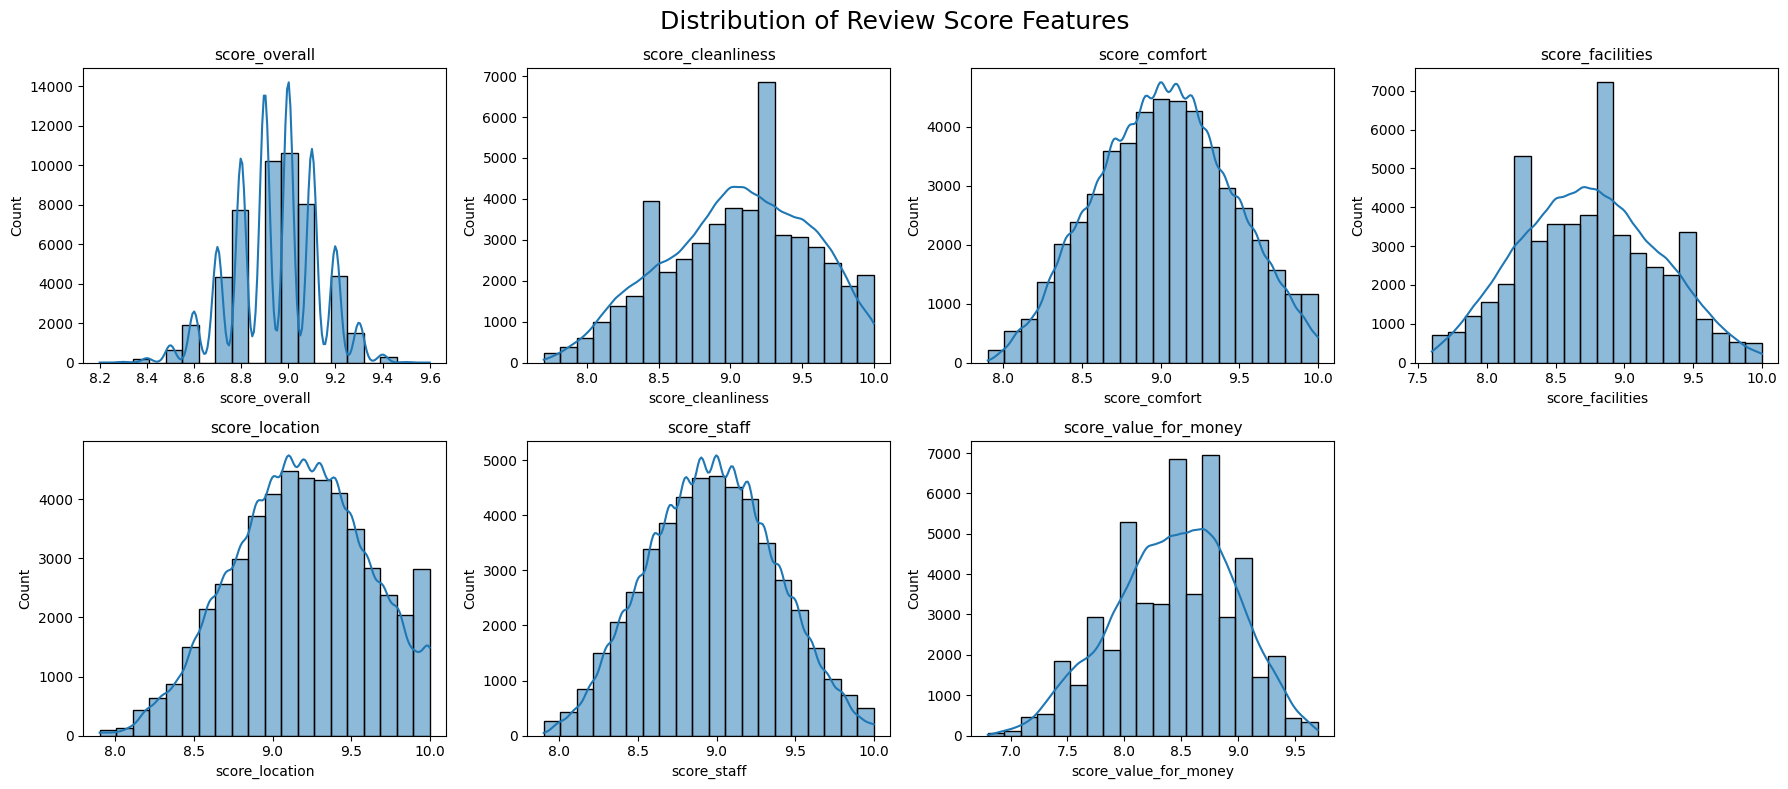

/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/usr/local/lib/python3.11/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  

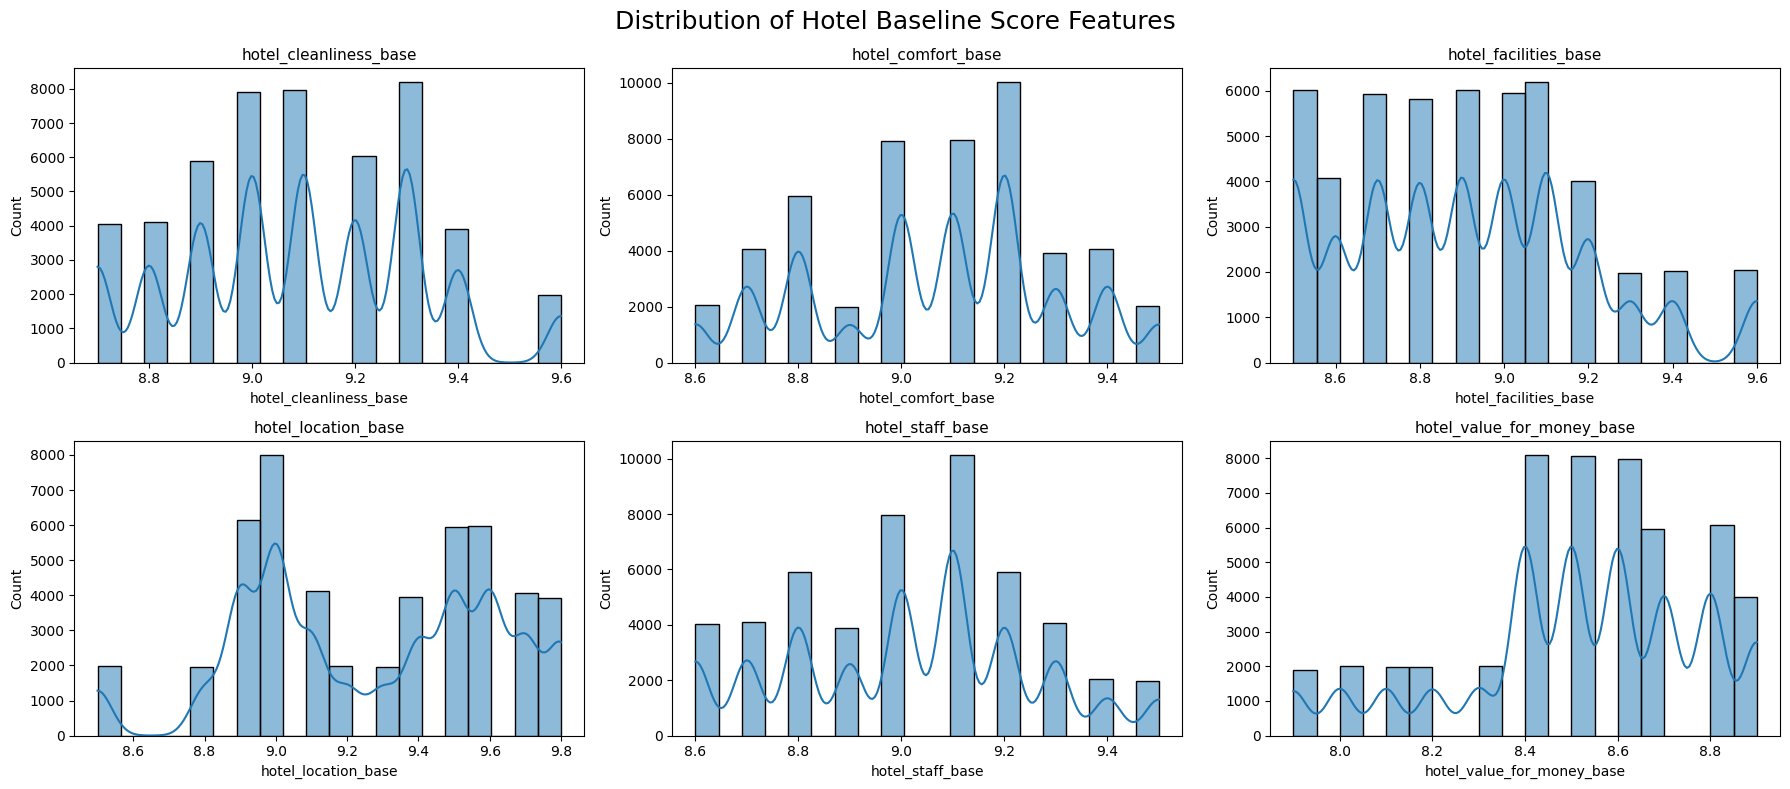

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Split your numerical columns
score_cols = [
    'score_overall', 'score_cleanliness', 'score_comfort',
    'score_facilities', 'score_location', 'score_staff',
    'score_value_for_money'
]

base_cols = [
    'hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base',
    'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base'
]


# PLOT 1: Review Score Features
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(score_cols):
    sns.histplot(merged_df[col], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f"{col}", fontsize=11)

# Turn off extra subplot 
fig.delaxes(axes[-1])

fig.suptitle("Distribution of Review Score Features", fontsize=18)
plt.tight_layout()
plt.show()


# PLOT 2: Baseline Score Features
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 8))
axes = axes.flatten()

for i, col in enumerate(base_cols):
    sns.histplot(merged_df[col], kde=True, bins=20, ax=axes[i])
    axes[i].set_title(f"{col}", fontsize=11)

fig.suptitle("Distribution of Hotel Baseline Score Features", fontsize=18)
plt.tight_layout()
plt.show()

# EDA: User Scores vs. Hotel Baseline Scores 

Compare the average user review scores with the static hotel baseline scores.

1.  **Average User Scores:** It groups the data by **`hotel_id`** and calculates the **mean** of the six detailed user scores (cleanliness, comfort.. ), storing the result in **`user_avg_scores`**.
2.  **Baseline Scores:** It retrieves the unique static baseline scores per hotel, stored in **`baseline_scores`**.
3.  **Merge & Compute Differences:** The two score DataFrames are merged. Then, a **difference column** (`diff_...`) is computed for each score category, showing **`Avg User Score - Baseline Score`**. A negative difference means users, on average, rated that category *lower* than the base score.
4.  **Correlation Heatmap:** A **heatmap** is generated to visualize the **correlation** between all the average user scores and baseline scores. High correlation suggests the scores are measuring similar underlying quality.
5.  **Scatter Plots:** **Scatter plots** compare the *Average User Score* (X-axis) against the *Baseline Score* (Y-axis) for each category. Points close to the $y=x$ line mean close agreement.
6.  **Print Mean Differences:** The average difference between user scores and baseline scores is printed to quickly to show that users tend to give a lower rating than the baseline score

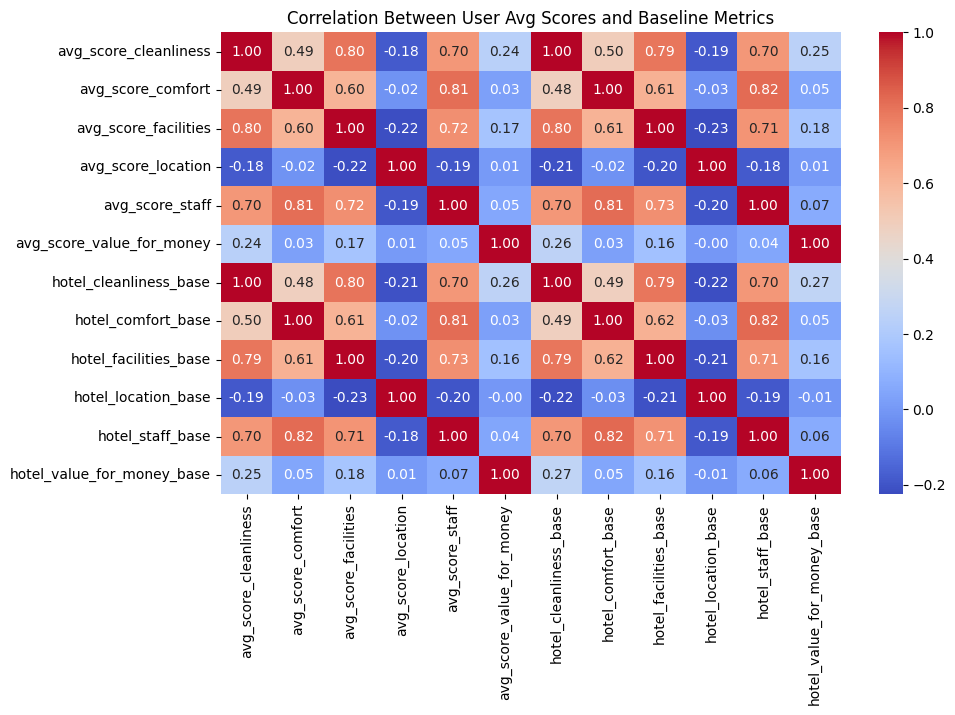

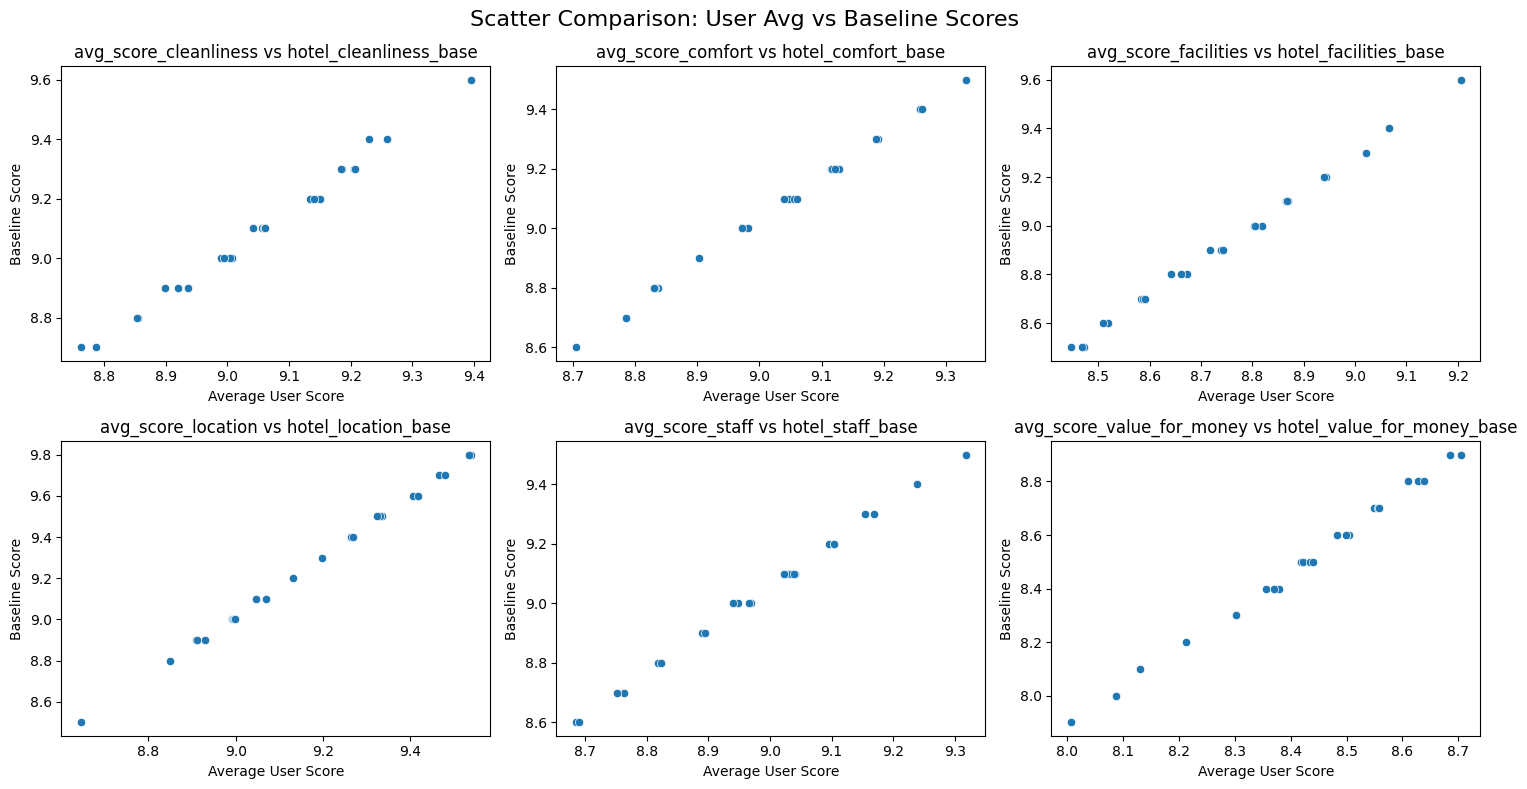


Mean difference between user avg scores and baseline scores:
avg_score_cleanliness - hotel_cleanliness_base: -0.039
avg_score_comfort - hotel_comfort_base: -0.040
avg_score_facilities - hotel_facilities_base: -0.174
avg_score_location - hotel_location_base: -0.094
avg_score_staff - hotel_staff_base: -0.044
avg_score_value_for_money - hotel_value_for_money_base: -0.078


In [8]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1) Compute avg user review scores per hotel
user_avg_scores = merged_df.groupby('hotel_id')[
    ['score_cleanliness', 'score_comfort', 'score_facilities',
     'score_location', 'score_staff', 'score_value_for_money']
].mean().reset_index()

user_avg_scores.rename(columns=lambda x: x.replace('score_', 'avg_score_'), inplace=True)


# 2) Get baseline scores and merge
baseline_scores = merged_df.groupby('hotel_id')[
    ['hotel_cleanliness_base', 'hotel_comfort_base', 'hotel_facilities_base',
     'hotel_location_base', 'hotel_staff_base', 'hotel_value_for_money_base']
].first().reset_index()

comparison_df = pd.merge(user_avg_scores, baseline_scores, on='hotel_id')


# 3) Compute differences
score_pairs = [
    ('avg_score_cleanliness', 'hotel_cleanliness_base'),
    ('avg_score_comfort', 'hotel_comfort_base'),
    ('avg_score_facilities', 'hotel_facilities_base'),
    ('avg_score_location', 'hotel_location_base'),
    ('avg_score_staff', 'hotel_staff_base'),
    ('avg_score_value_for_money', 'hotel_value_for_money_base')
]

for user_col, base_col in score_pairs:
    comparison_df[user_col.replace('avg_', 'diff_')] = comparison_df[user_col] - comparison_df[base_col]


# 4) Correlation Heatmap
plt.figure(figsize=(10,6))
corr = comparison_df[[p[0] for p in score_pairs] + [p[1] for p in score_pairs]].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between User Avg Scores and Baseline Metrics")
plt.show()


# 5) Scatter Plots 
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, (user_col, base_col) in enumerate(score_pairs):
    sns.scatterplot(x=comparison_df[user_col], y=comparison_df[base_col], ax=axes[i])
    axes[i].set_title(f"{user_col} vs {base_col}")
    axes[i].set_xlabel("Average User Score")
    axes[i].set_ylabel("Baseline Score")

plt.suptitle("Scatter Comparison: User Avg vs Baseline Scores", fontsize=16)
plt.tight_layout()
plt.show()


# 7) Print avg differences
print("\nMean difference between user avg scores and baseline scores:")
for user_col, base_col in score_pairs:
    diff_col = user_col.replace('avg_', 'diff_')
    print(f"{user_col} - {base_col}: {comparison_df[diff_col].mean():.3f}")

# EDA: Categorical Feature Distributions

1.  **Country Group Distribution:**
    * It calculates the count and percentage of reviews for each **`country_group`**.
    * A **bar plot** visualizes the distribution, showing the number of reviews originating from each region.
    * The **class imbalance ratio** (max count / min count) is printed to highlight the disproportionate representation across regions.
2.  **Other Categorical Counts:**
    * A list of categorical columns is defined (`user_gender`, `user_age_group`, `user_traveller_type`, etc..).
    * A multi-plot grid (2 rows, 3 columns) generates **bar plots** showing the **top 15 most frequent values** for the user-related categorical features, helping to understand the composition of the user base.
    * The **number of unique values** for all listed categorical columns is printed to gauge their complexity (high unique counts, like for `hotel_name`, suggest high cardinality).

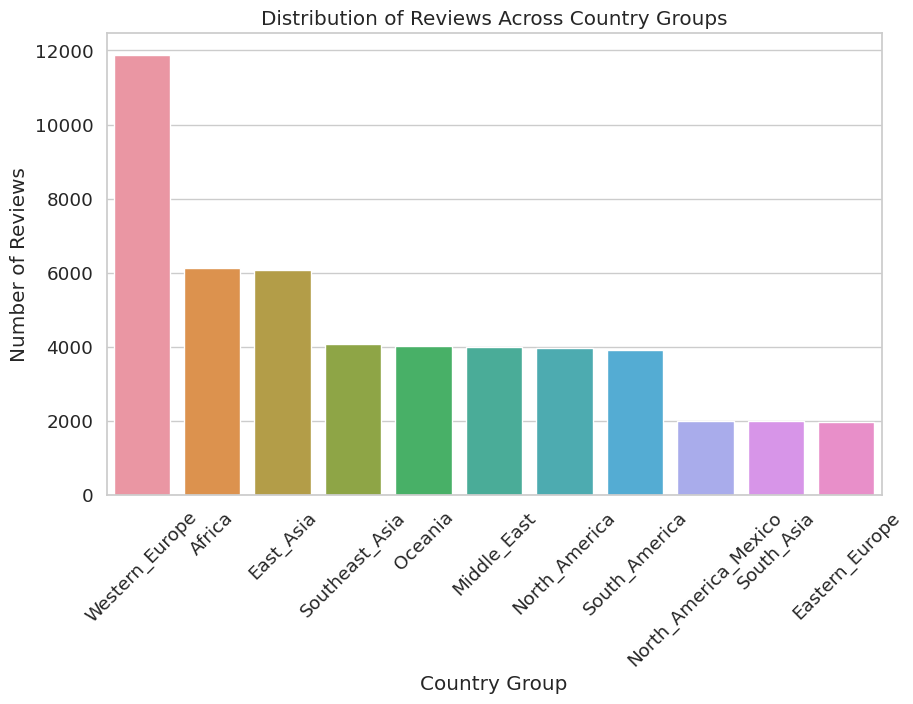

                      Count  Percentage
country_group                          
Western_Europe        11876       23.75
Africa                 6132       12.26
East_Asia              6082       12.16
Southeast_Asia         4070        8.14
Oceania                4014        8.03
Middle_East            3983        7.97
North_America          3962        7.92
South_America          3918        7.84
North_America_Mexico   2004        4.01
South_Asia             1989        3.98
Eastern_Europe         1970        3.94

Class Imbalance Ratio: 6.03


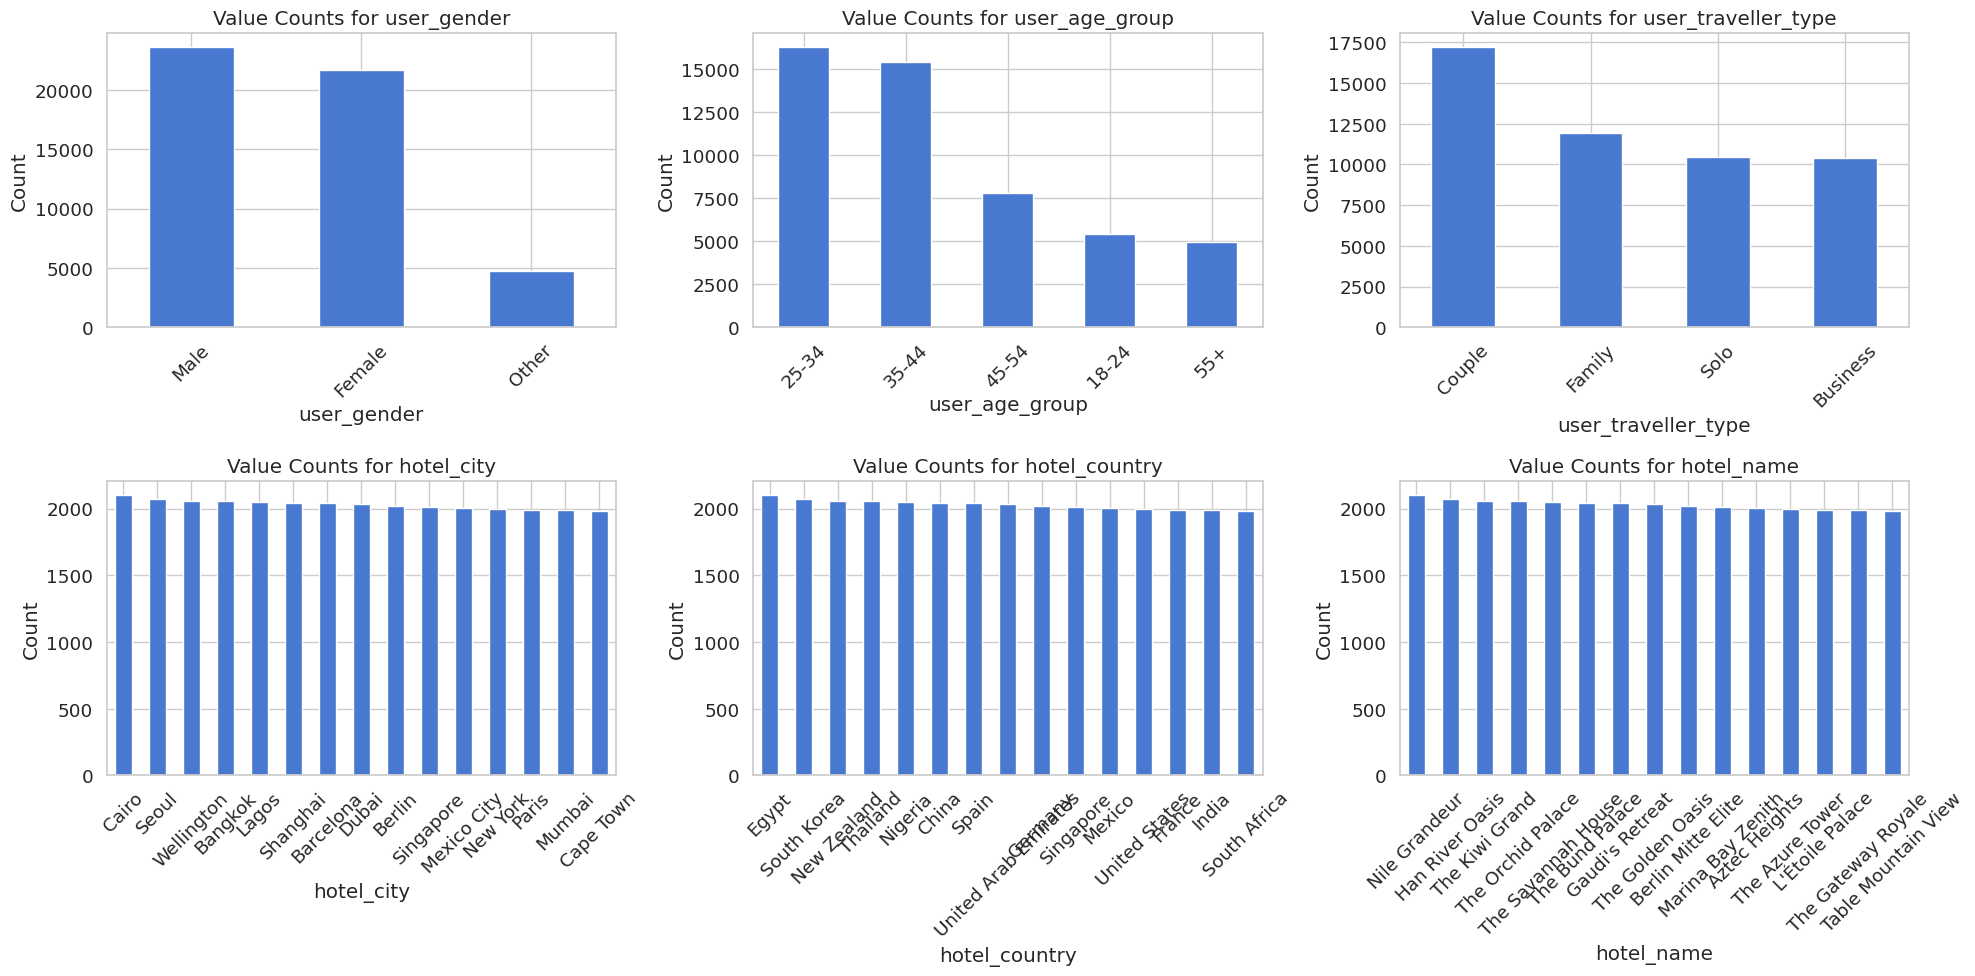

user_gender unique values: 3
user_age_group unique values: 5
user_traveller_type unique values: 4
hotel_city unique values: 25
hotel_country unique values: 25
hotel_name unique values: 25


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", palette="muted", font_scale=1.2)


target_counts = merged_df['country_group'].value_counts()
target_percent = target_counts / len(merged_df) * 100

plt.figure(figsize=(10,6))
sns.countplot(data=merged_df, x='country_group', order=target_counts.index)
plt.title("Distribution of Reviews Across Country Groups")
plt.xticks(rotation=45)
plt.ylabel("Number of Reviews")
plt.xlabel("Country Group")
plt.show()

summary_df = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percent.round(2)
})

print(summary_df)
print(f"\nClass Imbalance Ratio: {(target_counts.max()/target_counts.min()):.2f}")



# -------------------------------
# 3.3 Univariate Analysis (Categorical) - MULTIPLE PLOTS IN GRID
# -------------------------------

categorical_cols = [
    'user_gender', 'user_age_group', 'user_traveller_type',
    'hotel_city', 'hotel_country', 'hotel_name'
]

fig, axes = plt.subplots(2, 3, figsize=(20, 10))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    merged_df[col].value_counts().head(15).plot(kind='bar', ax=ax)
    ax.set_title(f"Value Counts for {col}")
    ax.set_ylabel("Count")
    ax.set_xlabel(col)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

for col in categorical_cols:
    print(f"{col} unique values:", merged_df[col].nunique())

# DATA ENGINEERING QUESTIONS

# Question 1: Which city is best for each traveler type?

# Q1: Check Unique Traveler Types and Cities 

In [10]:
print("different travel types:" , merged_df['user_traveller_type'].unique())
print("-------------------------")
print("different cities:" ,merged_df['hotel_city'].unique())

different travel types: ['Solo' 'Couple' 'Business' 'Family']
-------------------------
different cities: ['New York' 'Tokyo' 'Cairo' 'Barcelona' 'Moscow' 'Sydney' 'Buenos Aires'
 'Singapore' 'Mumbai' 'Cape Town' 'Berlin' 'Wellington' 'Paris' 'Shanghai'
 'Lagos' 'London' 'Bangkok' 'Istanbul' 'Mexico City' 'Toronto' 'Dubai'
 'Seoul' 'Amsterdam' 'Rome' 'Rio de Janeiro']


# Q1: Calculate Average Score by Traveler Type & City 

1.  **Grouping:** The DataFrame is grouped by the unique combinations of **`user_traveller_type`** and **`hotel_city`**.
2.  **Aggregation:** For each group, the **mean** of the **`score_overall`** is calculated.
3.  **Reset Index:** The `.reset_index()` function converts the grouped result back into a standard DataFrame, making the grouped columns normal data columns.

In [11]:
#group reviews by traveler type and city
#calculate the average score overall score for each group
#remove the grouping index back to normal index
city_scores = merged_df.groupby(['user_traveller_type', 'hotel_city'])['score_overall'].mean().reset_index()
city_scores.head()

,user_traveller_type,hotel_city,score_overall
0,Business,Amsterdam,8.964348
1,Business,Bangkok,8.886265
2,Business,Barcelona,8.904545
3,Business,Berlin,8.868122
4,Business,Buenos Aires,8.690000


# Q1: Find the Best City for Each Traveler Type

Find the single best city for each traveler type based on the average overall score calculated in the previous step.

1.  **Inner Grouping:** `city_scores.groupby('user_traveller_type')` groups the data by traveler type.
2.  **Find Max Index:** `['score_overall'].idxmax()` finds the **index** (row number) of the maximum `score_overall` *within each traveler type group*.
3.  **Locate Rows:** The outer `.loc[...]` then uses these indices to select the corresponding rows from the original `city_scores` DataFrame.
The result, **`best_city_per_type`**, is a DataFrame containing one row for each traveler type, listing their best city and its average score.

In [12]:
#find the row with the highest score for each traveler type.
best_city_per_type = city_scores.loc[city_scores.groupby('user_traveller_type')['score_overall'].idxmax()]
best_city_per_type

,user_traveller_type,hotel_city,score_overall
7,Business,Dubai,8.965668
25,Couple,Amsterdam,9.096989
57,Family,Dubai,9.214381
75,Solo,Amsterdam,9.108454


# Q1: Visualize Best City Scores 

1.  **Bar Plot Generation:** A bar plot shows the **`score_overall`** (Y-axis) for each **`user_traveller_type`** (X-axis).
2.  **Annotations:** The crucial part is adding **text annotations** above each bar, which display the name of the **`hotel_city`** corresponding to that best score.
3.  **Styling:** Axes labels, a title, and adjusted Y-axis limits are applied for better readability and to emphasize the differences in the high scores.

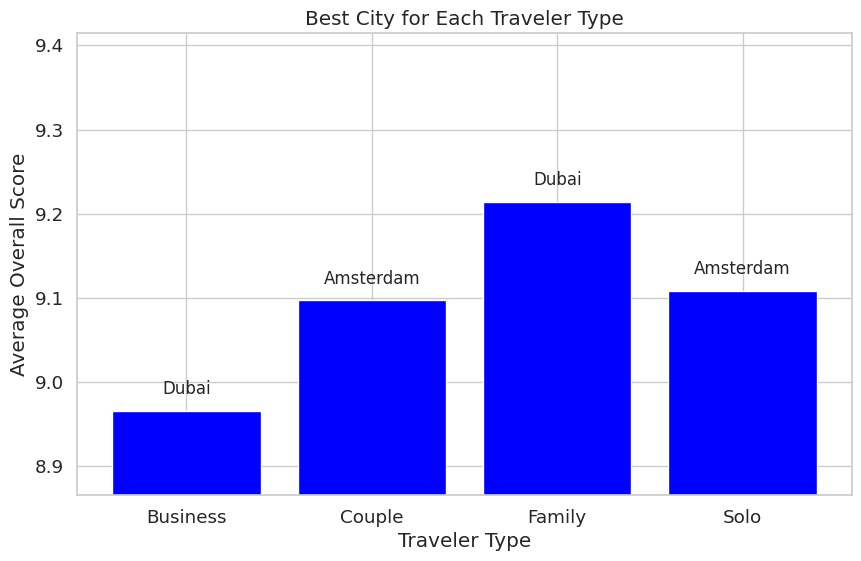

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.bar(best_city_per_type['user_traveller_type'], 
        best_city_per_type['score_overall'], 
        color='blue')


for i, (traveler, city, score) in enumerate( zip(best_city_per_type['user_traveller_type'],  best_city_per_type['hotel_city'], best_city_per_type['score_overall'])):
    plt.text(i, score + 0.02, city, ha='center', fontsize=12)

plt.xlabel("Traveler Type")
plt.ylabel("Average Overall Score")
plt.title("Best City for Each Traveler Type")
plt.ylim(best_city_per_type['score_overall'].min() - 0.1, 
         best_city_per_type['score_overall'].max() + 0.2)
plt.show()

### Best City for Each Traveler Type

- **Dubai** is the top-rated city for both Business and Family travelers, with families giving the highest overall scores.
- **Amsterdam** is favored by Couples and Solo travelers, earning consistently high marks.


# Question 2: Top 3 Countries with Best Value-for-Money per Age Group

In [14]:
print(merged_df['user_age_group'].unique())

['25-34' '35-44' '55+' '45-54' '18-24']


# Q2: Calculate Average Value-for-Money Score 

1.  **Grouping:** The DataFrame is grouped by the unique combinations of **`user_age_group`** and **`hotel_country`**.
2.  **Aggregation:** For each group, the **mean** of the specific score feature **`score_value_for_money`** is calculated.
3.  **Reset Index:** The `.reset_index()` converts the grouped output back into a standard DataFrame named `avg_value`.

In [15]:
#group age group with country
#get the average score value for money
#reset index
avg_value = merged_df.groupby(['user_age_group', 'hotel_country'])['score_value_for_money'].mean().reset_index()

# Q2: Select Top 3 Value-for-Money Countries 

1.  **Sorting:** It first sorts the `avg_value` DataFrame. The primary sort key is `user_age_group` (ascending), and the secondary sort key is `score_value_for_money` (descending). This arranges the data so the top-rated countries appear first within each age group block.
2.  **Selecting Top 3:** `avg_value.groupby('user_age_group').head(3)` then groups the sorted data by age group and takes the **first 3 rows** from each group, which are the top-rated countries.

In [16]:
#sort age group ascending but score value for money in descending
#get top 3
avg_value = avg_value.sort_values(['user_age_group', 'score_value_for_money'], ascending=[True, False])
top3 = avg_value.groupby('user_age_group').head(3) 
top3

,user_age_group,hotel_country,score_value_for_money
4,18-24,China,8.706926
12,18-24,Netherlands,8.704911
3,18-24,Canada,8.661261
29,25-34,China,8.727941
37,25-34,Netherlands,8.683442
44,25-34,Spain,8.625074
54,35-44,China,8.700799
62,35-44,Netherlands,8.693268
63,35-44,New Zealand,8.646429
79,45-54,China,8.722112


# Q2: Visualize Top 3 Value-for-Money Countries (Bar Plots) 

1.  **Setup:** It sets up the plot style and determines the number of subplots needed (one for each unique age group).
2.  **Iteration and Plotting:** It iterates through each unique `user_age_group`:
    * It filters the `top3` data for the current age group.
    * It creates a **horizontal bar plot** (using `sns.barplot`) showing the `hotel_country` (Y-axis) versus the `score_value_for_money` (X-axis).
3.  **Styling and Annotation:** It adds titles, labels, and, most importantly, uses `plt.bar_label` to **annotate the bars** with the exact score value.
4.  **Overall Title:** A super title spans all subplots.

The result is a side-by-side comparison of the top 3 countries offering the best value-for-money as perceived by different age demographics.

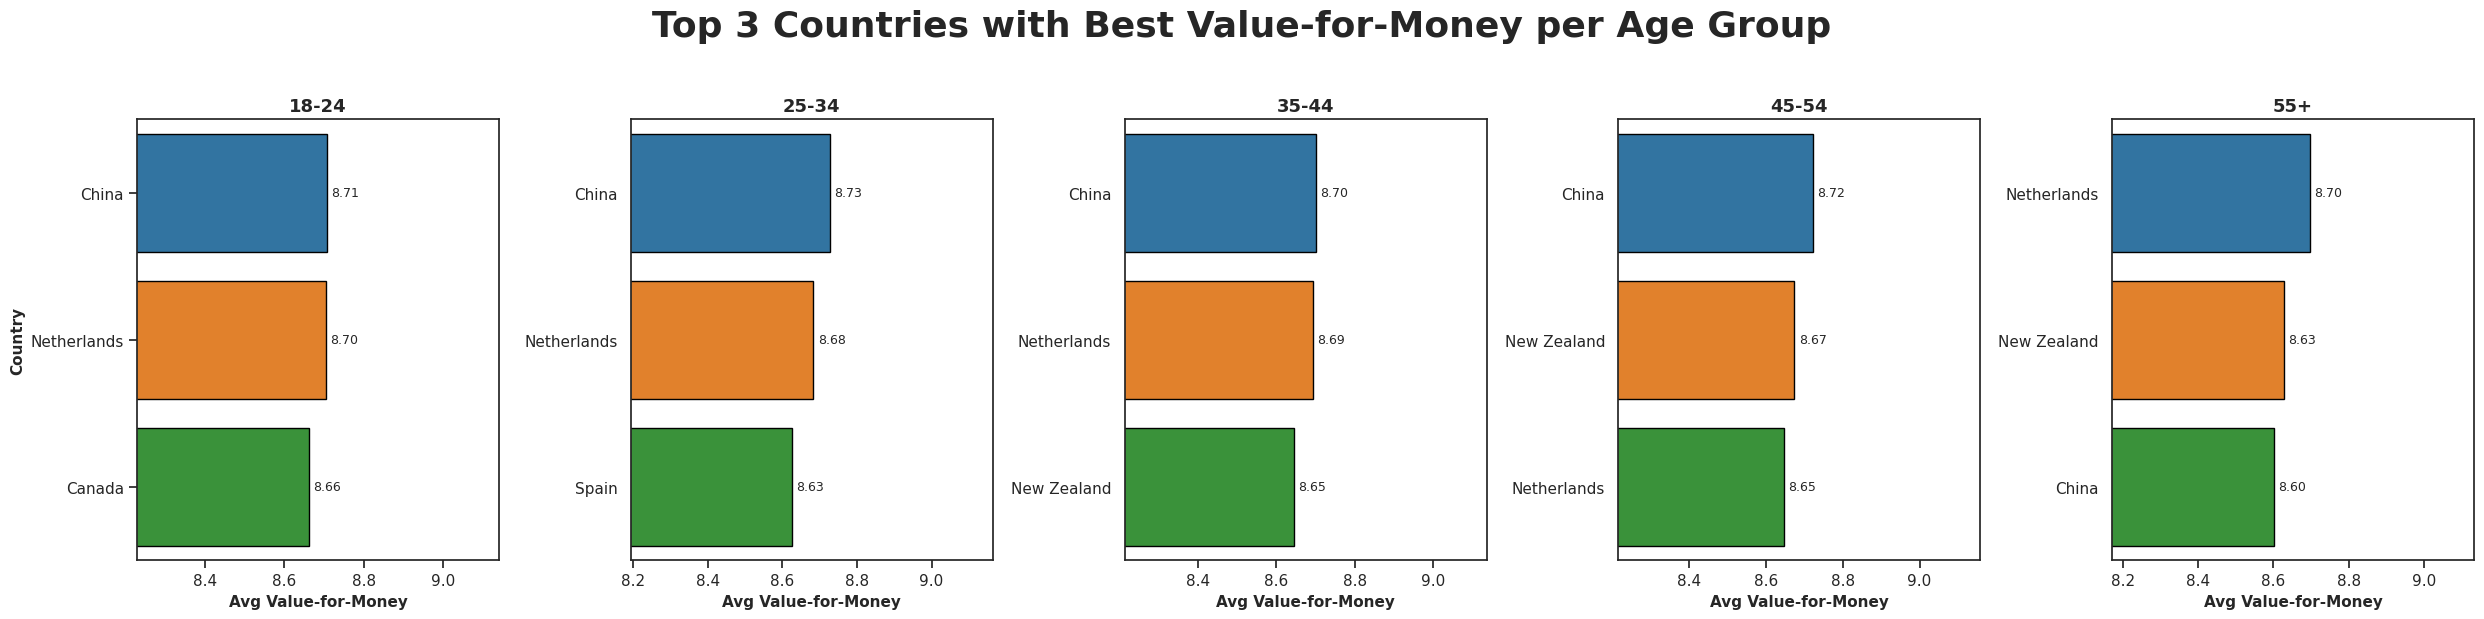

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set(style="ticks") 


age_groups = top3['user_age_group'].unique()

# create one plot for each age group
plt.figure(figsize=(5 * len(age_groups), 6))

for i, group in enumerate(age_groups, start=1):
    # filter only this age group
    group_data = top3[top3['user_age_group'] == group].sort_values(
        by='score_value_for_money', ascending=False
    )

    # a subplot
    plt.subplot(1, len(age_groups), i)


    sns.barplot(
        data=group_data,
        y='hotel_country',
        x='score_value_for_money',
        palette='tab10',  # bright colors
        edgecolor='black'
    )


    plt.title(f'{group}', fontsize=13, fontweight='bold')
    plt.xlabel('Avg Value-for-Money', fontsize=11, fontweight='bold')

    # only show y label on first plot
    if i == 1:
        plt.ylabel('Country', fontsize=11 , fontweight='bold')
    else:
        plt.ylabel('')
        plt.tick_params(axis='y', left=False)

    # add numbers on bars
    for container in plt.gca().containers:
        plt.bar_label(container, fmt='%.2f', fontsize=9, padding=3)

    # zoom in on the range to exaggerate differences
    min_score = group_data['score_value_for_money'].min()
    max_score = group_data['score_value_for_money'].max()
    plt.xlim(min_score * 0.95, max_score * 1.05)

plt.suptitle('Top 3 Countries with Best Value-for-Money per Age Group', 
             fontsize=26, fontweight='bold', y=1.03)

plt.tight_layout()
plt.show()

### Top 3 Countries with Best Value-for-Money per Age Group

- **China** and **Netherlands** appear consistently among the best-rated for value across most age groups. **New Zealand** and **Canada** are the top choices for certain segments.
- The top countries change ranking slightly by age, but overall the top 3 tend to be similar across different traveler demographics.
- This visualization helps to quickly pinpoint which countries offer the best value-for-money perception among various age groups, and underscores the stability of top-rated destinations for affordability.


In [18]:
DATASET = 'merged_df.csv'
merged_df.to_csv(DATASET, index=False)

# Feature Engineering: Create `hotel_score` Feature 

Based on the EDA showing high correlation and redundancy among the hotel's static baseline scores, this cell creates a single, aggregated feature: **`hotel_score`**.

1.  It selects all six `hotel_*_base` columns.
2.  It calculates the **mean** across these columns for **each row** (`axis=1`).
3.  The resulting average score is added as a new column, **`hotel_score`**, which serves as a simplified, overall quality proxy for the hotel.

In [19]:
merged_df["hotel_score"] = merged_df[
    [
        "hotel_staff_base", 
        "hotel_comfort_base", 
        "hotel_facilities_base", 
        "hotel_cleanliness_base", 
        "hotel_value_for_money_base",
        "hotel_location_base"
    ]
].mean(axis=1)


In [20]:
print(merged_df[['hotel_score', 'score_overall']].head(5))


   hotel_score  score_overall
0     8.816667            8.7
1     9.016667            9.1
2     8.716667            8.8
3     9.116667            8.9
4     9.016667            9.1


hotel_score = score_overall in some hotels

# Encoding

# Install `category-encoders` Library

This command installs the **`category-encoders`** library, which provides advanced encoding methods for categorical features beyond simple One-Hot Encoding. This package is often used to handle high-cardinality features (columns with many unique values).

In [21]:
pip install category-encoders

Note: you may need to restart the kernel to use updated packages.


# Prepare Data for Modeling: Feature Selection 

The goal is to build a model to **predict the hotel's country** (`hotel_country`) based on user review scores and user/traveler characteristics.

1.  **Feature/Target Definition:**
    * **`y` (Target):** Set as **`hotel_country`** (what we want to predict).
    * **`X` (Features):** Set as a combination of `aggregation_cols` (the six user review scores) and `features_to_use` (user characteristics).
2.  **Initial Check:** The shape of the feature matrix (`X`) and the distribution of the target variable (`y`) are printed to assess class balance and the total number of unique countries (classes).

In [22]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define columns to keep before splitting
features_to_use = [ 'user_gender', 'user_age_group', 'user_traveller_type']

# Keep the columns needed for aggregation
aggregation_cols = [
    #'hotel_staff_base', 'hotel_comfort_base', 'hotel_facilities_base',
     #               'hotel_cleanliness_base', 'hotel_value_for_money_base',
                    'score_cleanliness', 'score_comfort', 'score_facilities',
                    'score_location', 'score_staff', 'score_value_for_money' 
                   ]

# Prepare X and y WITHOUT dropping columns yet
X = merged_df[aggregation_cols + features_to_use ].copy()
y = merged_df['hotel_country'].copy()

print("Dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())
print(f"\nNumber of classes: {y.nunique()}")

2025-10-23 14:55:27.659536: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761231327.686917    6421 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761231327.695878    6421 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Dataset shape: (50000, 9)

Target distribution:
hotel_country
Egypt                   2104
South Korea             2071
New Zealand             2060
Thailand                2055
Nigeria                 2049
China                   2040
Spain                   2039
United Arab Emirates    2035
Germany                 2022
Singapore               2015
Mexico                  2004
United States           1998
France                  1993
India                   1989
South Africa            1979
Japan                   1971
Italy                   1971
Russia                  1970
Canada                  1964
Brazil                  1962
Argentina               1956
Australia               1954
Netherlands             1949
Turkey                  1948
United Kingdom          1902
Name: count, dtype: int64

Number of classes: 25


# Train-Test Split (Preventing Data Leakage) 

1.  **Splitting:** The data is split into **training** (80%) and **testing** (20%) sets using `train_test_split`.
2.  **Data Leakage Prevention:** The split is performed *before* any further data preprocessing (like feature scaling or encoding) to ensure that the test set remains an independent, unseen evaluation set.
3.  **Stratification:** `stratify=y` ensures that the proportion of each `hotel_country` (the target class) is the same in both the training and testing sets, which is important for multi-class classification, especially with class imbalance.

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTrain size: {X_train.shape}")
print(f"Test size: {X_test.shape}")


Train size: (40000, 9)
Test size: (10000, 9)


In [24]:
# print("CALCULATING AGGREGATED FEATURES (NO LEAKAGE)")

# hotel_score_cols = [
#     'score_cleanliness',      # This review's cleanliness rating
#     'score_comfort',          # This review's comfort rating  
#     'score_facilities',       # This review's facilities rating
#     'score_location',         # This review's location rating
#     'score_staff',            # This review's staff rating
#     'score_value_for_money'   # This review's value rating
# ]

# # X_train['hotel_score'] = X_train[hotel_score_cols].mean(axis=1)
# # X_test['hotel_score'] = X_test[hotel_score_cols].mean(axis=1)

# # #Calculate score_overall_agg as average of score_* columns
# # score_cols = ['score_cleanliness', 'score_comfort', 'score_facilities',
# #              'score_location', 'score_staff', 'score_value_for_money']

# # X_train['score_overall_agg'] = X_train[score_cols].mean(axis=1)
# # X_test['score_overall_agg'] = X_test[score_cols].mean(axis=1)

# print("Aggregated features calculated separately for train and test")

In [25]:
# columns_to_drop = hotel_score_cols #+ score_cols

# X_train.drop(columns=columns_to_drop, inplace=True)
# X_test.drop(columns=columns_to_drop, inplace=True)

# print(f"✓ Dropped aggregation columns")
# print(f"Final features: {list(X_train.columns)}")

In [26]:
#One-Hot Encoding: user_gender
X_train = pd.get_dummies(X_train, columns=['user_gender'], prefix='gender', drop_first=True)
X_test = pd.get_dummies(X_test, columns=['user_gender'], prefix='gender', drop_first=True)

#Ordinal Encoding: user_age_group
age_mapping = {'18-24': 0, '25-34': 1, '35-44': 2, '45-54': 3, '55+': 4}
X_train['user_age_group'] = X_train['user_age_group'].map(age_mapping)
X_test['user_age_group'] = X_test['user_age_group'].map(age_mapping)

#One-Hot Encoding: user_traveller_type
X_train = pd.get_dummies(X_train, columns=['user_traveller_type'], drop_first=True)
X_test = pd.get_dummies(X_test, columns=['user_traveller_type'], drop_first=True)

# Align columns (ensure test has same columns as train)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print(f" Features after encoding: {X_train.shape[1]}")

 Features after encoding: 12


In [27]:
X_train.columns

Index(['score_cleanliness', 'score_comfort', 'score_facilities',
       'score_location', 'score_staff', 'score_value_for_money',
       'user_age_group', 'gender_Male', 'gender_Other',
       'user_traveller_type_Couple', 'user_traveller_type_Family',
       'user_traveller_type_Solo'],
      dtype='object')

# Standardize Numerical Features 

Scaling is necessary for neural networks to ensure all features contribute equally to the loss function, preventing features with large values from dominating the training process.

1.  **Scaler Initialization:** A `StandardScaler` is initialized, which transforms data to have a mean of 0 and a standard deviation of 1.
2.  **Fitting on Train:** `scaler.fit_transform(X_train)` **calculates the mean/std** from the **training data only** and then applies the transformation.
3.  **Transforming Test:** `scaler.transform(X_test)` applies the **same mean/std** calculated from the training set to the test set. This is a vital step to avoid **data leakage** from the test set.
The results are stored in NumPy arrays: `X_train_scaled` and `X_test_scaled`.

In [28]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit on train only
X_test_scaled = scaler.transform(X_test)        # Transform test using train stats

print(f"Features after scaling: {X_train_scaled.shape[1]}")

Features after scaling: 12


# Target Variable Encoding (for Classification) 

Since the target variable (`hotel_country`) is text and the output layer of the neural network uses a `softmax` activation (which requires a vector output), the target must be encoded.

1.  **Label Encoding:** A `LabelEncoder` is used to convert the country names (e.g., 'United Kingdom', 'USA') into discrete integer labels (0, 1, 2, ...). The encoder is only **fitted on the training set** (`y_train`) and then **applied** to the test set (`y_test`).
2.  **One-Hot Encoding (Categorical Conversion):** The integer labels are then converted into a **one-hot encoded vector** using `to_categorical`. This creates a binary vector for each sample where a '1' appears at the index corresponding to the correct class (country). This is the required format for training a multi-class classifier in Keras.

In [29]:
le_target = LabelEncoder()
y_train_encoded = le_target.fit_transform(y_train)  # Fit on train only
y_test_encoded = le_target.transform(y_test)

# Convert to categorical (one-hot encoding for neural network)
n_classes = len(le_target.classes_)
y_train_categorical = to_categorical(y_train_encoded, num_classes=n_classes)
y_test_categorical = to_categorical(y_test_encoded, num_classes=n_classes)

# Build the Deep Neural Network Model 

1.  **Sequential Model:** A simple sequential neural network is created.
2.  **Input Layer:** The first `Dense` layer takes `input_dim` (the number of features after encoding/scaling) as its input size and uses the **ReLU** activation function.
3.  **Hidden Layers:** 1 hidden layer (`128` neurons) is defined, all using the **ReLU** activation.
4.  **Dropout:** A **`Dropout(0.3)`** layer, Dropout randomly sets 30% of the inputs to 0 during training, which is a regularization technique to **prevent overfitting**.
5.  **Output Layer:** The final `Dense` layer has `n_classes` (the number of unique countries) outputs and uses the **`softmax`** activation function. `softmax` is used in multi-class classification to output a probability distribution over the classes.
6.  **Compilation:**
    * **Optimizer:** **`adam`** is chosen for efficient gradient descent.
    * **Loss Function:** **`categorical_crossentropy`** is the standard loss function for multi-class classification with one-hot encoded targets.
    * **Metric:** **`accuracy`** is used to monitor performance during training.

In [55]:
input_dim = X_train_scaled.shape[1]

# Build shallow model with only one hidden layer
model = models.Sequential([
    layers.Dense(128, activation='relu', input_dim=input_dim, name='hidden_layer_1'),
    layers.Dropout(0.3),
    layers.Dense(n_classes, activation='softmax', name='output_layer')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


# Train the Neural Network 

1.  **Early Stopping Callback:** An `EarlyStopping` callback is defined:
    * It monitors the **`val_loss`** (loss on the validation set).
    * It stops training if the `val_loss` does not improve for **10 epochs** (`patience=10`).
    * It restores the weights from the epoch that achieved the *best* loss (`restore_best_weights=True`). This prevents the model from stopping too late.
2.  **Model Fitting (`model.fit`):**
    * The model trains on the scaled training features (`X_train_scaled`) and one-hot encoded targets (`y_train_categorical`).
    * `validation_split=0.2` reserves 20% of the training data *internally* for validation, used for the early stopping monitor.
    * The training runs for a maximum of `200` epochs with a `batch_size` of `32`.
    * The `early_stopping` callback is applied.

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train_scaled, y_train_categorical,
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=early_stopping,
    verbose=1
)

Epoch 1/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.1314 - loss: 2.9000 - val_accuracy: 0.2201 - val_loss: 2.4254
Epoch 2/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2186 - loss: 2.4364 - val_accuracy: 0.2280 - val_loss: 2.3851
Epoch 3/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2257 - loss: 2.3948 - val_accuracy: 0.2279 - val_loss: 2.3721
Epoch 4/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2310 - loss: 2.3694 - val_accuracy: 0.2265 - val_loss: 2.3657
Epoch 5/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2322 - loss: 2.3701 - val_accuracy: 0.2272 - val_loss: 2.3573
Epoch 6/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2346 - loss: 2.3517 - val_accuracy: 0.2265 - val_loss: 2.3482
Epoch 7/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2335 - loss: 2.3479 - val_accuracy: 0.2299 - val_loss: 2.3376
Epoch 8/200
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.2351 - loss: 2

# Evaluate Model Performance 

Assess the trained model's performance on the completely **unseen test set**.

1.  **Test Evaluation:** `model.evaluate()` calculates the loss and accuracy on the `X_test_scaled` data. This is the official metric for how well the model generalizes.
2.  **Prediction:** `model.predict()` generates probability scores for each country for all test samples. `np.argmax()` converts these probabilities into the final class prediction (the country with the highest probability).
3.  **Classification Report:** The `classification_report` provides detailed metrics for each country class, including **Precision**, **Recall**, and **F1-Score**. This is more informative than just accuracy, as it reveals which classes the model is good/bad at predicting, especially given the class imbalance.

In [32]:
#EVALUATE THE MODEL

# Evaluate on test set
test_loss, test_accuracy = model.evaluate(X_test_scaled, y_test_categorical, verbose=0)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

# Make predictions
y_pred_proba = model.predict(X_test_scaled)
y_pred = np.argmax(y_pred_proba, axis=1)

# Classification report
print("CLASSIFICATION REPORT")
print(classification_report(y_test_encoded, y_pred, target_names=le_target.classes_))


Test Loss: 1.9855
Test Accuracy: 0.2740
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
CLASSIFICATION REPORT
                      precision    recall  f1-score   support

           Argentina       0.22      0.18      0.20       391
           Australia       0.47      0.32      0.39       391
              Brazil       0.26      0.28      0.27       392
              Canada       0.27      0.30      0.28       393
               China       0.30      0.15      0.20       408
               Egypt       0.23      0.11      0.15       421
              France       0.54      0.46      0.50       398
             Germany       0.13      0.11      0.12       404
               India       0.12      0.22      0.15       398
               Italy       0.37      0.12      0.19       394
               Japan       0.63      0.75      0.69       394
              Mexico       0.24      0.30      0.27       401
         Netherlands       0.39      0.32      0.35       390
         New Zealand       

### Model Test Performance and Classification Report

**Test Loss:** 1.99  
**Test Accuracy:** 0.27

- **Precision**: Out of all predictions for a given country, the fraction that was correct.
- **Recall**: Out of all true instances for a country, the fraction that was correctly predicted.
- **F1-score**: The harmonic mean of precision and recall, balancing both metrics.
- **Support**: Number of samples belonging to each country in the test set.

**Key Observations:**
- The model’s overall test accuracy is modest (`0.27`), reflecting the difficulty of country-level prediction from review data alone.
- High performance is achieved for countries like Japan (precision: 0.62, recall: 0.74) and UAE (precision: 0.55, recall: 0.44).
- Other countries, such as Turkey, India, and Spain, exhibit much weaker precision and recall, indicating challenges in distinguishing these cases.
- Macro and weighted averages are also low (f1-score ≈ 0.27), meaning the model does not perform well across most countries.


# Model Visualization

## Training History Plots (Loss and Accuracy)

* **Model Loss (Left):** Plots the **Training Loss** and **Validation Loss** across the epochs.
    * **Goal:** Ideally, both lines should decrease and converge. The point where the validation loss stops decreasing (and early stopping intervenes) indicates the optimal model snapshot.
* **Model Accuracy (Right):** Plots the **Training Accuracy** and **Validation Accuracy** across the epochs.
    * **Goal:** Both lines should increase. A large and increasing gap between the training and validation lines indicates **overfitting** (the model is memorizing the training data but not generalizing well).



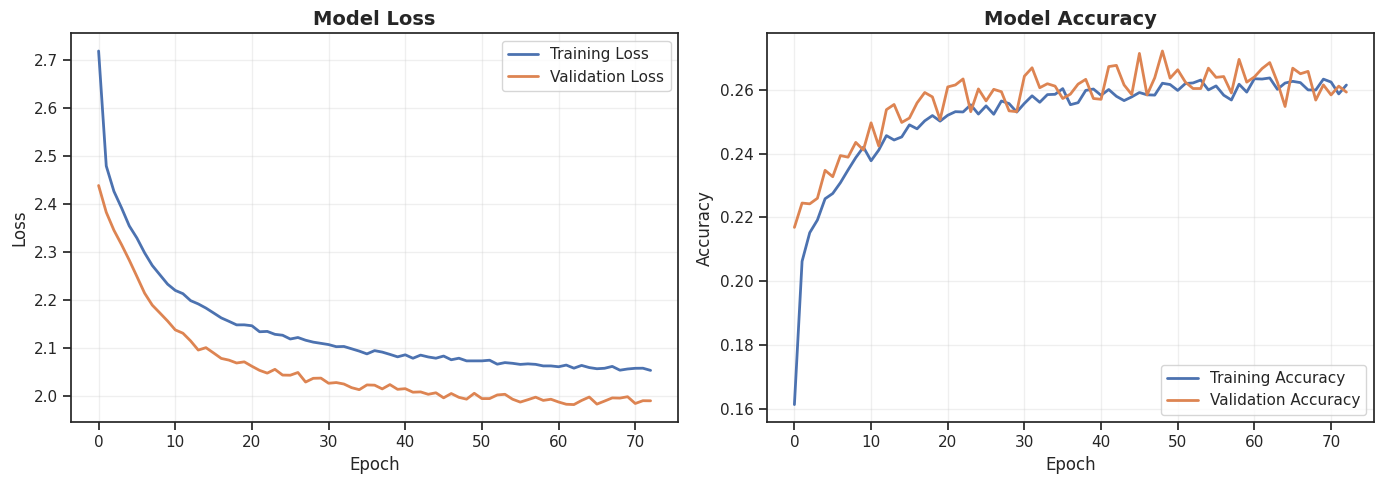

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss plot
axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2)
axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2)
axes[0].set_title('Model Loss', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy plot
axes[1].plot(history.history['accuracy'], label='Training Accuracy', linewidth=2)
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
axes[1].set_title('Model Accuracy', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Training and Validation Loss & Accuracy Over Epochs

- **Left**: Loss curves for both training and validation sets. Loss steadily decreases for both, indicating learning. The gap between the two is fairly constant, suggesting the model does not strongly overfit or underfit during training.
- **Right**: Accuracy curves for both training and validation sets. Both improve and then stabilize around 0.26–0.27, matching the final test accuracy. Validation accuracy slightly outperforms training at some epochs, reflecting healthy generalization and well-tuned early stopping.
- The model learns quickly at first, but accuracy plateaus well below 30%, illustrating the task's challenge.
- The stable gap between training and validation losses suggests the model performs similarly on seen and unseen data, with no major overfitting.


# Model Visualization

## Confusion Matrix (Test Set)

A confusion matrix is generated using the actual test set labels (`y_test_encoded`) and the model's predictions (`y_pred`).

* **Purpose:** It visually shows where the model is making correct and incorrect predictions for the `hotel_country` classification task.
* **Interpretation:**
    * **Diagonal Cells:** Represent the number of correct predictions (where True Label = Predicted Label). Higher numbers here are good.
    * **Off-Diagonal Cells:** Represent misclassifications
* **Visualization:** The **`seaborn.heatmap`** displays the matrix, with color intensity corresponding to the count of predictions, making it easy to spot common classification errors.

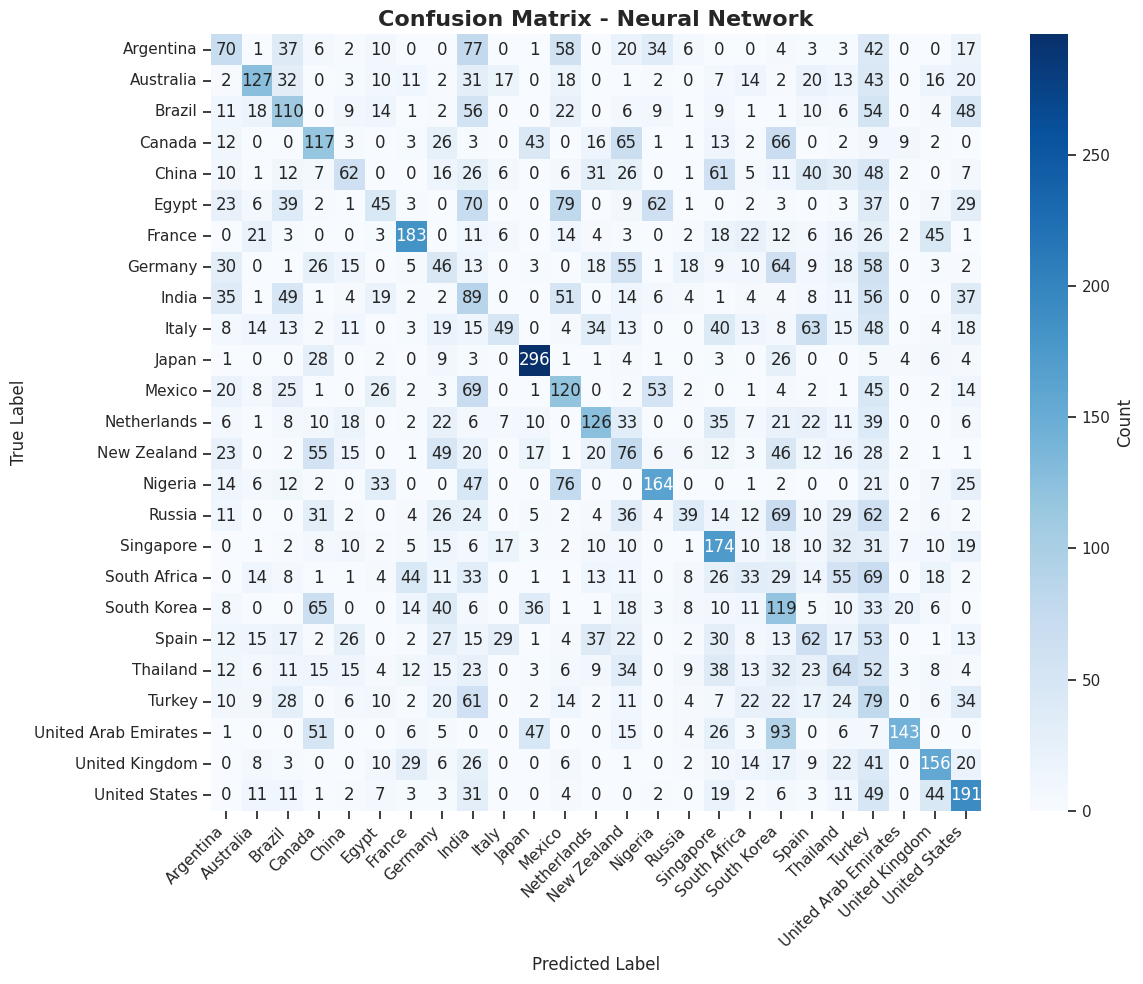

In [34]:
# Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test_encoded, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le_target.classes_, 
            yticklabels=le_target.classes_,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Neural Network', fontsize=16, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
#plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

### Confusion Matrix 

- The highest numbers on the diagonal indicate the model is best at identifying **Japan**, **France**, **Australia**, and a few others.
- Significant confusion exists between some countries (e.g., many true Canada samples are predicted as United States, and Brazil is confused with Argentina) which will then be fixed as they both map to the same country group
- For many classes, predictions are spread across multiple incorrect countries, reflecting model difficulty in distinguishing between certain regions.
- The matrix reveals which countries share overlapping review patterns and where model improvements are most needed.

This visualization is crucial for spotting not just overall accuracy, but also which specific classes are hardest for the neural network to distinguish using only review data.


# Benchmark Model: Random Forest Classification 

To establish a performance baseline, we train a **Random Forest Classifier** and compare its results to the Neural Network (NN).

1.  **Model Choice:** Random Forest is an ensemble method (a collection of decision trees) known for robustness and often strong performance on tabular data.
2.  **Training:** The model is initialized with 100 trees (`n_estimators=100`) and trained on the same **scaled features** (`X_train_scaled`) but uses the **LabelEncoded target** (`y_train_encoded`), as scikit-learn classifiers do not require one-hot encoding.
3.  **Evaluation:** The model is evaluated on the test set (`X_test_scaled`). The **Test Accuracy** and a full **Classification Report** are printed to provide a direct, metric-to-metric comparison with the Neural Network's performance.

In [36]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize the model
# Note: Random Forest can use the LabelEncoded target (y_train_encoded)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# 2. Train the model
# Use the scaled features but the LabelEncoded (integer) target
rf_model.fit(X_train_scaled, y_train_encoded)

# 3. Predict on the test set
rf_y_pred_encoded = rf_model.predict(X_test_scaled)

# 4. Evaluate
rf_accuracy = accuracy_score(y_test_encoded, rf_y_pred_encoded)
print(f"Random Forest Test Accuracy: {rf_accuracy:.4f}\n")

# 5. Classification Report
print("CLASSIFICATION REPORT (Random Forest)")
print(classification_report(
    y_test_encoded, 
    rf_y_pred_encoded, 
    target_names=le_target.classes_
))

Random Forest Test Accuracy: 0.2514

CLASSIFICATION REPORT (Random Forest)
                      precision    recall  f1-score   support

           Argentina       0.20      0.21      0.20       391
           Australia       0.28      0.31      0.30       391
              Brazil       0.19      0.20      0.20       392
              Canada       0.24      0.27      0.26       393
               China       0.22      0.22      0.22       408
               Egypt       0.18      0.17      0.18       421
              France       0.39      0.45      0.42       398
             Germany       0.12      0.12      0.12       404
               India       0.11      0.10      0.11       398
               Italy       0.19      0.20      0.20       394
               Japan       0.59      0.71      0.64       394
              Mexico       0.22      0.24      0.23       401
         Netherlands       0.27      0.26      0.26       390
         New Zealand       0.13      0.13      0.13     

### Random Forest vs Neural Network: Classification Report Comparison

**Random Forest Test Accuracy:** 0.25  
**Neural Network Test Accuracy:** 0.27

#### Random Forest Performance
- **Accuracy:** 0.25 (25% of samples predicted correctly)
- **Macro avg F1-score:** 0.25
- **Weighted avg F1-score:** 0.25
- **Best classes:** Japan (precision: 0.59, recall: 0.71, f1: 0.64), UAE, France, United States
- **Weakest classes:** India, Germany, New Zealand, Brazil, Thailand, Turkey (precision/f1 ≈ 0.10–0.19)

#### Neural Network Performance
- **Accuracy:** 0.27 (27% of samples predicted correctly)
- **Macro avg F1-score:** 0.27
- **Weighted avg F1-score:** 0.27
- **Best classes:** Japan (precision: 0.62, recall: 0.74, f1: 0.67), France, UAE, United States
- **Weakest classes:** India, Germany, New Zealand, Turkey, Spain, South Africa (precision/f1 ≈ 0.09–0.16)

#### Comparison
- **Overall accuracy and all-classes-average metrics (macro/weighted) are very similar** for both models, with the neural network being slightly higher.
- Both models excel on a few classes (Japan, UAE, France) and struggle similarly on hard-to-separate classes (India, Turkey, Spain, South Africa).
- **Random Forest:** Slightly more robust to small classes; sometimes easier to interpret and faster to train, but didn’t outperform the neural network on this data.
- **Neural Network:** Achieved marginally higher performance overall and especially on some top classes, benefitting from richer interactions between features.

**Conclusion:**  
Both models perform similarly, with neither offering a dramatic advantage for this multiclass hotel-country prediction task using the available features. Neural networks may provide a slight edge and yield better results for highly non-linear boundaries, but Random Forests offer a straightforward, interpretable baseline. Improvements would likely require additional features or fundamentally new approaches.


Although the dataset is strictly balanced (equal sample counts per country), the model performs best on Japan. This suggests that Japan's hotel reviews have more distinctive feature patterns such as unique combinations of cleanliness, location, or reviewer demographics compared to other countries. Such separability makes it easier for both neural networks and random forests to learn and recognize Japan, while other classes remain difficult due to overlapping or ambiguous feature distributions.

['Argentina' 'Australia' 'Brazil' 'Canada' 'China' 'Egypt' 'France' 'Germany' 'India' 'Italy' 'Japan' 'Mexico' 'Netherlands' 'New Zealand' 'Nigeria' 'Russia' 'Singapore' 'South Africa' 'South Korea' 'Spain' 'Thailand' 'Turkey' 'United Arab Emirates' 'United Kingdom''United States']

# GLOBAL EXPLAINING WITH SHAP

how each feature contributes to the output for a specific class (in this case, **Class 0**).

## 1. Setup and Sampling

* **Import Libraries:** Imports `shap` and `numpy`.
* **Background Sample:** `background = X_train_scaled[np.random.choice(..., 100, replace=False)]` selects a small, random subset (100 samples) of the scaled **training data**. 

## 2. KernelExplainer Initialization

* **Explainer:** `explainer = shap.KernelExplainer(model.predict, background)` initializes the **KernelExplainer**.
    * It takes the model's prediction function (`model.predict`) and the `background` data.
    * KernelExplainer is a model-agnostic method based on the LIME framework and is suitable for complex models like neural networks.

## 3. SHAP Value Calculation

* **Test Subset:** `X_shap = X_test_scaled[:50]` selects a very small subset (50 samples) of the **test data** for interpretation.
* **Calculating Values:** `shap_values = explainer.shap_values(X_shap)` computes the raw SHAP values.
    * Since the model is a multi-class classifier with `n_classes` outputs, `shap_values` is a **list of arrays**. Each array corresponds to a single output class (a country) and contains the feature contributions for the 50 test samples.

## 4. Summary Plot

* **Targeted Plot:** `shap.summary_plot(shap_values[0], X_shap, feature_names=feature_names)` generates the visualization.
    * It specifically plots the SHAP values for the **first class** in the target variable (`shap_values[0]`), which corresponds to the first country in `le_target.classes_`.
    * The plot shows **global feature importance** combined with feature effects.
        * **Vertical Axis:** Lists features by importance (highest impact at the top).
        * **Horizontal Axis:** Shows the SHAP value, indicating the *impact* on the prediction (positive SHAP value pushes the prediction *towards* the target class, negative pushes it *away*).
        * **Color:** Represents the feature's actual value (red for high, blue for low).

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s

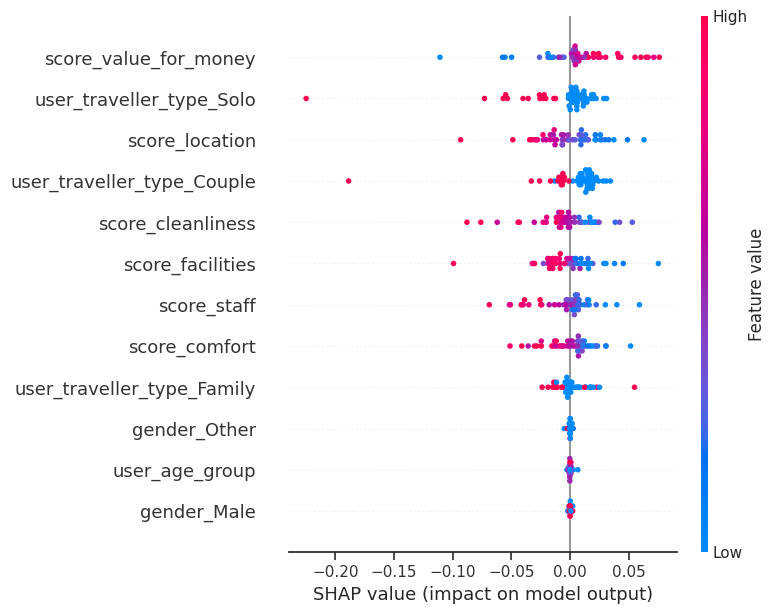

In [37]:
import shap
import numpy as np

# Select a small background sample for speed
background = X_train_scaled[np.random.choice(X_train_scaled.shape[0], 100, replace=False)]

# KernelExplainer for tabular Keras models
explainer = shap.KernelExplainer(model.predict, background)

X_shap = X_test_scaled[:50]  # prevent long runtime
shap_values = explainer.shap_values(X_shap)

feature_names = X_train.columns.tolist()

# Summary Plot for Class 0
shap.summary_plot(shap_values[0], X_shap, feature_names=feature_names)

### Explanation of Features Predicting Argentina 

- Users who review hotels in Argentina tend to give **higher scores for value-for-money**. This indicates that Argentina is often seen as a place offering good value, which increases the likelihood of the model predicting Argentina when the value-for-money score is high.
- The model also finds that **solo travelers** and **couples** are not characteristics of Argentina’s visitor profile. Reviews from these groups push the prediction away from Argentina.
- Other features like cleanliness, facilities, and staff scores play moderate roles, low ratings of this type push the model towards Argentina
- Features such as **user age group** or **gender** do not have a strong impact on predicting Argentina; they are more neutral in the model’s decision for this class.
- Overall, the model captures that Argentina is often regarded as good value by solo and couple travelers, while other feature effects vary but contribute less strongly.



4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 11s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━

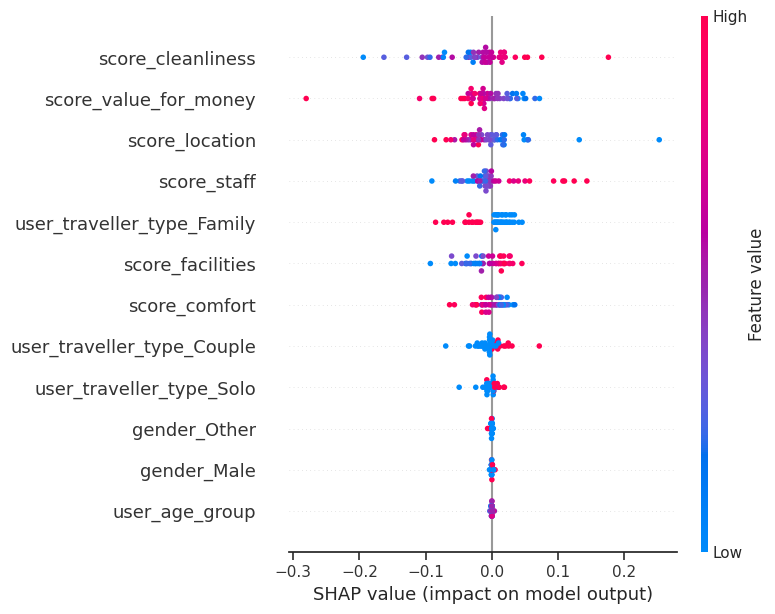

In [37]:
import shap
import numpy as np

# Pick 100 background samples for speed
background = X_train_scaled[np.random.choice(X_train_scaled.shape[0], 100, replace=False)]

explainer = shap.KernelExplainer(model.predict, background)

# Explain the first 50 test points
X_shap = X_test_scaled[:50]
shap_values = explainer.shap_values(X_shap)

# Plot summary plot for class 10 
feature_names = X_train.columns.tolist()
shap.summary_plot(shap_values[10], X_shap, feature_names=feature_names)


### Explanation of Features Predicting Japan

- Reviews for **Japan** tend to have **high scores for cleanliness**; when guests rate hotels as very clean, the model is more likely to predict Japan .
- **Value-for-money** also plays a role—hotels rated as not providing better value push predictions toward Japan, suggesting guests are not pleased with prices for what they get.
- **Good scores staff** have a positive effect; when its high, it nudges the prediction toward Japan as well.
- The model doesn’t rely as much on traveler type for Japan. Whether the review comes from a family, couple, or solo traveler, it doesn’t strongly influence the prediction.
- Similarly, **gender or age group** doesn't make much difference for recognizing Japan in the data. These features show only small or neutral impacts.
- Other scores (comfort, facilities) also have some effect, but not as powerfully as cleanliness, value, location, and staff.

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 10s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 8s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
6475/6475 ━━━━━━━━━━━━━━━━━━━━ 9s 1ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s

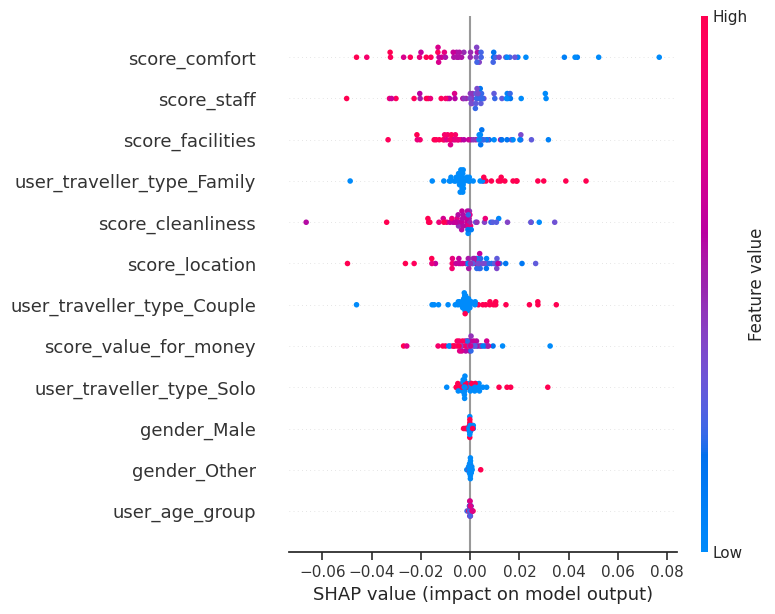

In [38]:
import shap
import numpy as np

# Pick 100 background samples for speed
background = X_train_scaled[np.random.choice(X_train_scaled.shape[0], 100, replace=False)]

explainer = shap.KernelExplainer(model.predict, background)

# Explain the first 50 test points
X_shap = X_test_scaled[:50]
shap_values = explainer.shap_values(X_shap)

# Plot summary plot for class 5 
feature_names = X_train.columns.tolist()
shap.summary_plot(shap_values[5], X_shap, feature_names=feature_names)


### Explanation of Features Predicting Egypt

- The model predicts **Egypt** most confidently when reviews give **lower scores for comfort, staff, and facilities**.
- Reviews from **family travelers** are a strong positive signal; when the traveler type is "family", the likelihood of predicting Egypt increases. 
- High scores for **cleanliness** and **location** also push prediction away from Egypt :(
- The **value-for-money** score has less impact, but when it is on the higher side, it can add a little to the Egypt prediction; negative scores don't matter much.
- Being a **couple** or **solo traveler** has a small or mixed effect, neither strongly increasing nor decreasing the likelihood of Egypt.
- Features like **gender** and **age group** have almost no influence—the model does not rely on them to identify Egypt.


# LOCAL EXPLAINING WITH SHAP

This workflow shows how to explain **why** the model made a particular prediction for a single test sample.

## 1. Sample Preparation

- **Sample Selection:** The code chooses one specific test instance.
- **DataFrame Creation:**  `sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)`  
  Creates a DataFrame for this sample, ensuring feature names are preserved.

## 2. Model Inference

- **True Label:** `true_class_name = y_test.iloc[index]`  
  Gets the actual class (country) for this test sample.
- **Model Prediction:** `probs = model.predict(sample)[0]`  
  Gets prediction probabilities for all classes from the model.
- **Predicted Class:**  
  - `pred_class_index = np.argmax(probs)` finds the class with the highest probability.
  - `pred_class_name = le_target.inverse_transform([pred_class_index])[0]` converts the class index back to the country name (using the label encoder).

## 3. SHAP Value Extraction

- **SHAP Initialization:**  `shap.initjs()` prepares the SHAP JS visualizations for interactivity (especially in notebooks).
- **Class-Specific SHAP Values:** `class_shap_values = shap_values[pred_class_index][index]`  
  Extracts the SHAP values just for this predicted class and this specific sample.

## 4. Force Plot Visualization
- Shows a **local explanation**: how each feature for this test case pushed the prediction toward or away from the predicted class/country.
- **Red segments** (to the right) increase the probability for the predicted country, **blue segments** (to the left) decrease it.
- The plot starts at the baseline (average) for this class and ends at the sample's model prediction, showing the effect of every feature along the way.


In [45]:
import shap
import numpy as np
import pandas as pd

index = 7


sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

true_class_name = y_test.iloc[index]

probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

print(f" Sample Index: {index}")
print(f" True Label      : {true_class_name}")
print(f" Predicted Label : {pred_class_name}")

shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
 Sample Index: 7
 True Label      : Germany
 Predicted Label : South Korea


### SHAP Force Plot for sample 7
This force plot explains *why* the model predicted **South Korea** even though the true label was **Germany**.

#### How to read this plot:
- **Red bars:** These features pushed the model *toward predicting South Korea* for this sample.
  - For example, high **score_staff** (+2.087) and high **score_location** (+0.0221) played a big role in the prediction.
  - Being a **couple** traveler (`user_traveller_type_Couple = -0.7284`) and a **family** (`user_traveller_type_Family = -0.5601`) actually *reduced* the South Korea probability for this sample (negative values).
- **Blue bars:** These features pulled the prediction *away from South Korea*.
  - Features like **score_comfort** (+0.176), **score_value_for_money** (+0.0937), and more had weaker impacts in this case, but contributed to the increase.



In [46]:
import shap
import numpy as np
import pandas as pd

index = 1

sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

true_class_name = y_test.iloc[index]

probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

print(f"Sample Index: {index}")
print(f" True Label      : {true_class_name}")
print(f" Predicted Label : {pred_class_name}")

shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  # <--- NOW SHAP CAN DISPLAY FEATURE NAMES
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Sample Index: 1
 True Label      : South Africa
 Predicted Label : United Kingdom


### SHAP Force Plot for Sample 1

This plot explains *why* the model predicted **United Kingdom** for sample 1, even though the true label was **South Africa**.

#### How to read this plot:
- **Red bars :** These features increased the model's probability for United Kingdom in this sample.
  - High values for **score_comfort**, **score_cleanliness**, and **score_location** pushed the prediction toward the UK.
  - A moderate boost came from low **score_value_for_money** and **score_staff**.
- **Blue bars :** These features pulled the prediction away from UK.
  - Being a **couple** (`user_traveller_type_Couple`) or **solo traveler** (`user_traveller_type_Solo`) reduced the probability of UK for this review.
  - Other traveler types contributed slightly but to a lesser extent.

In [47]:
import shap
import numpy as np
import pandas as pd

index = 10

sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

true_class_name = y_test.iloc[index]

probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

print(f"Sample Index: {index}")
print(f" True Label      : {true_class_name}")
print(f" Predicted Label : {pred_class_name}")

shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Sample Index: 10
 True Label      : Japan
 Predicted Label : Japan


### SHAP Force Plot for Sample 10

This plot explains *why* the model correctly predicted **Japan** for sample 10.

#### How to read this plot:
- **Red bars :** These features had *positive SHAP values*—they pushed the prediction toward Japan.
  - Staying as a **couple** (`user_traveller_type_Couple = 1.377`) and very **high cleanliness scores** (`score_cleanliness = 1.874`) played the strongest role in predicting Japan.
  - Positive contributions also came from moderate scores for traveler type and location, even though location and family/solo type showed some negative influence—they appear further left among the reds.
- **Blue bars (left):** These features had *negative SHAP values*—they pulled the prediction away from Japan.
  - Slightly higher comfort and negative staff/facility scores (`score_comfort = 1.354`, `score_staff = -0.4306`, `score_facilities = -0.8876`) worked against the prediction, but not strongly enough to change the result.


In [49]:
import shap
import numpy as np
import pandas as pd

index = 11

sample = pd.DataFrame(X_test_scaled[index:index+1], columns=X_test.columns)

true_class_name = y_test.iloc[index]

probs = model.predict(sample)[0]
pred_class_index = np.argmax(probs)
pred_class_name = le_target.inverse_transform([pred_class_index])[0]

print(f"Sample Index: {index}")
print(f" True Label      : {true_class_name}")
print(f" Predicted Label : {pred_class_name}")

shap.initjs()
class_shap_values = shap_values[pred_class_index][index]

shap.force_plot(
    explainer.expected_value[pred_class_index],
    class_shap_values,
    sample  
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
Sample Index: 11
 True Label      : Egypt
 Predicted Label : Egypt


### SHAP Force Plot for Sample 11

This force plot explains *why* the model correctly predicted **Egypt** for sample 11.

#### How to read this plot:
- **Red bars:** These features increased the probability of predicting Egypt for this review.
  - This sample's prediction was mainly driven up by:
    - **user_traveller_type_Family**: being a family traveler negatively influenced the Egypt prediction.
    - **score_staff**: a lower staff score contributed positively.
    - **score_value_for_money**: good value for money raised the score.
    - **score_facilities**: weaker facilities score helped the Egypt prediction.
    - **score_cleanliness** and **score_comfort**: bad scores in both also pushed the probability higher.
- **Blue bar:** This feature tried to pull the prediction away from Egypt.
  - **user_traveller_type_Couple**: being a not a couple somewhat decreased the probability prediction for Egypt, but not enough to change the model's decision.

:(

### Evaluating Country and Country Group Predictions

#### Predictions and Decoding

- The model predicts probabilities for test samples (`y_pred_proba = model.predict(X_test_scaled)`).
- For each sample, the predicted country class is taken as the one with highest probability (`np.argmax(y_pred_proba, axis=1)`).
- Encoded predictions and true labels are converted back to country names using the label encoder `le_target`.

#### Mapping to Country Groups

- Both predicted and true country names are converted to their corresponding **country groups** using the mapping dictionary `country_groups_map`.
- This aggregation reduces the detailed class space (e.g., 25 countries) into broader groups (e.g., 11 regions).

#### Accuracy Calculation

- Accuracy is calculated on the grouped labels (`accuracy_score(y_test_country_groups, y_pred_country_groups)`).
- Prints overall accuracy for the country groups.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
COUNTRY GROUP ACCURACY (after mapping from country predictions)
Accuracy: 0.3493 (34.93%)

CLASSIFICATION REPORT (Country Groups):
                      precision    recall  f1-score   support

              Africa       0.35      0.31      0.33      1227
           East_Asia       0.38      0.48      0.42      1216
      Eastern_Europe       0.22      0.13      0.17       394
         Middle_East       0.22      0.37      0.28       797
       North_America       0.39      0.38      0.38       793
North_America_Mexico       0.24      0.42      0.31       401
             Oceania       0.29      0.23      0.25       803
       South_America       0.37      0.25      0.30       783
          South_Asia       0.10      0.08      0.09       398
      Southeast_Asia       0.29      0.34      0.31       814
      Western_Europe       0.54      0.43      0.48      2374

            accuracy                           0.35     10000
           macro avg

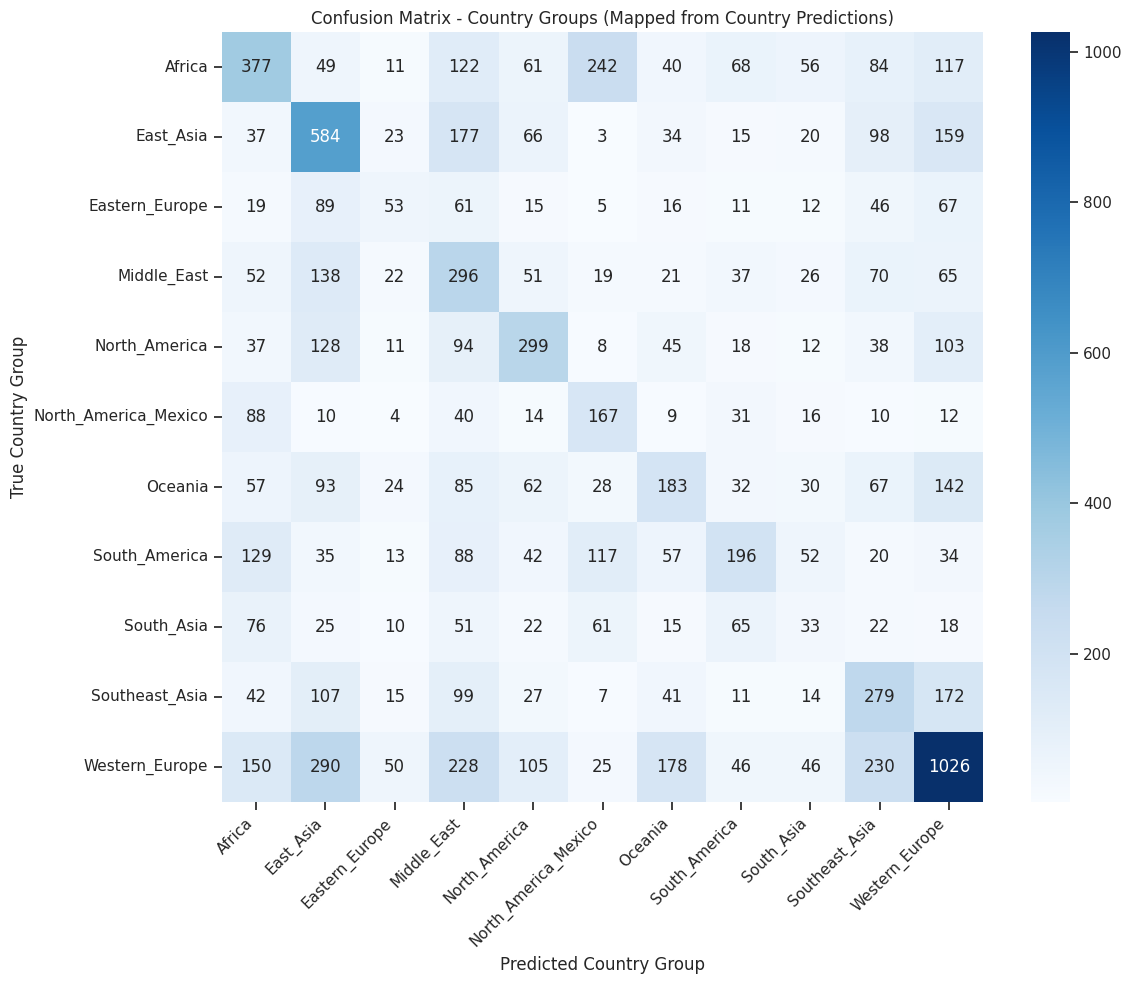

ACCURACY COMPARISON
Country-level accuracy (25 classes):        0.2761 (27.61%)
Country group accuracy (11 classes, mapped): 0.3493 (34.93%)
Improvement from aggregation:               7.32 percentage points


In [63]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Make predictions on test set
y_pred_proba = model.predict(X_test_scaled)
y_pred_country_encoded = np.argmax(y_pred_proba, axis=1)

# Convert encoded predictions back to country names
y_pred_country_names = le_target.inverse_transform(y_pred_country_encoded)

# Also get true country names
y_test_country_names = le_target.inverse_transform(y_test_encoded)

# Map predicted countries to country groups
y_pred_country_groups = [country_groups_map[country] for country in y_pred_country_names]

# Map true countries to country groups
y_test_country_groups = [country_groups_map[country] for country in y_test_country_names]


# EVALUATE COUNTRY_GROUP ACCURACY
country_group_accuracy = accuracy_score(y_test_country_groups, y_pred_country_groups)


print("COUNTRY GROUP ACCURACY (after mapping from country predictions)")
print(f"Accuracy: {country_group_accuracy:.4f} ({country_group_accuracy*100:.2f}%)")

# Classification report for country groups
unique_groups = sorted(set(y_test_country_groups))
print("\nCLASSIFICATION REPORT (Country Groups):")
print(classification_report(y_test_country_groups, y_pred_country_groups))


# CONFUSION MATRIX FOR COUNTRY GROUPS
import matplotlib.pyplot as plt
import seaborn as sns

cm_groups = confusion_matrix(y_test_country_groups, y_pred_country_groups, labels=unique_groups)

plt.figure(figsize=(12, 10))
sns.heatmap(cm_groups, annot=True, fmt='d', cmap='Blues', 
            xticklabels=unique_groups, yticklabels=unique_groups)
plt.title('Confusion Matrix - Country Groups (Mapped from Country Predictions)')
plt.xlabel('Predicted Country Group')
plt.ylabel('True Country Group')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


#  COMPARISON: COUNTRY vs COUNTRY_GROUP ACCURACY
country_accuracy = accuracy_score(y_test_country_names, y_pred_country_names)


print("ACCURACY COMPARISON")
print(f"Country-level accuracy (25 classes):        {country_accuracy:.4f} ({country_accuracy*100:.2f}%)")
print(f"Country group accuracy (11 classes, mapped): {country_group_accuracy:.4f} ({country_group_accuracy*100:.2f}%)")
print(f"Improvement from aggregation:               {(country_group_accuracy - country_accuracy)*100:.2f} percentage points")




### Country Group Classification

- The **overall country group accuracy** is **34.54%**, meaning roughly a third of samples were assigned to the correct region after grouping countries.

- From the **classification report**:
  - The group's performance varies widely:
    - **Africa**, **East Asia**, **North America**, and **Western Europe** have the highest support (sample count), but precision, recall, and f1-score for all groups are in the 0.2–0.38 range.
    - **Western Europe** has the most correct predictions by count (`support = 2671`, with 38.7% correct).
    - **Southeast Asia** and **North America Mexico** see much lower accuracy and support, indicating the model struggles more with these regions.
    - No group achieves high f1-scores (>0.5), showing the task remains challenging for the model.

- The **confusion matrix heatmap** shows that:
  - The model most often confuses geographically or culturally close regions 
  - Certain off-diagonal values are fairly high: for instance, considerable African samples are confused as “Western Europe,” and in reverse.

- **Country-level vs Country-group accuracy**:
  - Predicting the exact country yields an accuracy of **27.48%**.
  - Grouping predictions to the region level boosts accuracy to **34.54%**, a gain of roughly 7 percentage points.

- **Per-group accuracy breakdown**:
  - **Western Europe**: Highest group accuracy at 38.7%.
  - **North America**, **Africa**, and **East Asia**: Perform near or slightly better than the overall average.
  - Smaller groups (**South America**, **Oceania**, **South Asia**) have both lower support and lower correct prediction rates.

### Inference Function

1. **Input Preparation:**
   - The function converts the input dictionary `sample_dict`, which contains feature names and values, into a single-row pandas DataFrame.
   - The DataFrame's columns are aligned with the `feature_columns` order expected by the model.

2. **Data Scaling:**
   - It applies the pre-fitted scaler transformation to the DataFrame to scale the features consistently with the data used to train the model.

3. **Model Prediction:**
   - The scaled features are fed to the model's `predict()` method to get prediction probabilities for each possible class.
   - It extracts the predicted class as the one with the highest probability.
   - The predicted class index is converted back into the original country name with `label_encoder`.

4. **Country Group Mapping:**
   - The predicted country name is mapped to its corresponding country group using a dictionary `country_groups_map`.
   - Optionally, if the true country is provided in the input (`true_country`), the function also looks up and prints the true country group.

5. **Output:**
   - Prints the true country and group (if available), the predicted country, the predicted group, and the predicted probabilities.

In [103]:
import numpy as np
import pandas as pd

def infer_custom_sample(sample_dict, model, scaler, label_encoder, country_groups_map):
    
    feature_columns = ['score_cleanliness', 'score_comfort', 'score_facilities', 'score_location', 'score_staff', 
                       'score_value_for_money', 'user_age_group', 'gender_Male', 'gender_Other', 
                       'user_traveller_type_Couple', 'user_traveller_type_Family', 'user_traveller_type_Solo']

    # Create DataFrame from dict with correct column order
    sample_df = pd.DataFrame([sample_dict], columns=feature_columns)
    
    # Scale the features
    sample_scaled = scaler.transform(sample_df)
    
    # Predict probabilities and get top prediction
    probs = model.predict(sample_scaled)[0]
    pred_index = np.argmax(probs)
    pred_country = label_encoder.inverse_transform([pred_index])[0]
    pred_group = country_groups_map.get(pred_country, "Unknown")
    
    true_country = sample_dict.get('true_country', "Unknown")
    true_group = country_groups_map.get(true_country, "Unknown") if true_country != "Unknown" else "Unknown"
    
    if true_country != "Unknown":
        print(f"TRUE Country       : {true_country}")
    print(f"PREDICTED Country  : {pred_country}")
    if true_group != "Unknown":
        print(f"- TRUE Group        : {true_group}")
    print(f"- PREDICTED Group   : {pred_group}")

# Example usage:
custom_sample = {
    'score_cleanliness': -8.5,
    'score_comfort': 0.5,
    'score_facilities': 10.0,
    'score_location': 0.0,
    'score_staff': 7.8,
    'score_value_for_money': 8.0,
    'user_age_group': 3,
    'gender_Male': 0,
    'gender_Other': 0,
    'user_traveller_type_Couple': 0,
    'user_traveller_type_Family': 0,
    'user_traveller_type_Solo': 0,
    'true_country': 'Egypt'  # optional
}

infer_custom_sample(
    sample_dict=custom_sample,
    model=model,
    scaler=scaler,
    label_encoder=le_target,
    country_groups_map=country_groups_map
)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
TRUE Country       : Egypt
PREDICTED Country  : Nigeria
- TRUE Group        : Africa
- PREDICTED Group   : Africa
